# Sujet de TP : Création d'un système de question/réponse sur Wikipédia

Dans ce TP, vous allez travailler sur un extrait de Wikipédia en français publié sur Hugging Face (`kaitchup/wikipedia-20220301-fr-sample-10k`). Le code de démarrage vous permet de télécharger, filtrer (articles entre 200 et 900 mots) et stocker 1000 documents dans un DataFrame.

Votre objectif est de construire un système RAG complet : découper le texte, l'indexer pour la recherche, et utiliser un LLM pour générer une réponse à partir des documents retrouvés.

---

## Partie 1 : Découpage des documents (Chunking)

Les modèles d'embedding et les LLM ont une limite de taille de contexte (nombre de tokens maximum). Il est donc indispensable de découper les articles Wikipédia en plus petits morceaux *chunks*.

**Question 1 : Implémentez deux stratégies de chunking au choix parmi les trois suivantes :**

*   Fenêtre fixe (Fixed-size) : Découper le texte par blocs d'un nombre fixe de mots ou de caractères (ex: 500 caractères), avec un léger chevauchement (*overlap*) de 50 caractères pour ne pas couper le sens d'une phrase.
*   Récursif (Recursive) : Découper le texte en essayant de respecter la structure du langage (d'abord par paragraphes `\n\n`, puis par phrases `. `, puis par mots) jusqu'à atteindre la taille maximale désirée.
*   Sémantique (Semantic) : Regrouper les phrases dont le sens est similaire (en utilisant des embeddings) pour former des chunks qui abordent exactement le même sous-sujet.

**Travail attendu :**
1. Écrivez le code pour appliquer les deux méthodes de votre choix sur la colonne `body` de votre DataFrame.
2. Créez une nouvelle structure de données (ex: liste de dictionnaires) où chaque élément est un "chunk" associé à l'ID et au titre de son document d'origine.
3. Comparez la taille et la cohérence visuelle de quelques chunks générés par la première méthode vs la deuxième. Laquelle vous semble la plus pertinente pour des articles Wikipédia ?

---

## Partie 2 : Indexation et recherche de l'information (Retrieval)

Maintenant que vous avez vos chunks, vous devez créer un moteur de recherche capable de trouver les passages pertinents pour répondre à une question utilisateur.

**Question 2.1 : Indexation lexicale (TF-IDF)**
L'approche lexicale cherche les mots exacts en commun entre la question et les documents, en pondérant par leur rareté.
*   Utilisez `TfidfVectorizer` (de scikit-learn) pour ajuster un modèle sur l'ensemble de vos chunks.
*   Écrivez une fonction `search_tfidf(query, k=5)` qui transforme la requête et renvoie les `k` chunks ayant la plus grande similarité cosinus avec la requête.

**Question 2.2 : Indexation sémantique (Dense Vector)**
L'approche dense cherche le sens de la phrase, même si les mots sont différents, grâce aux plongements vectoriels (embeddings).
*   Utilisez le modèle `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2` pour encoder tous vos chunks sous forme de vecteurs.
*   Écrivez une fonction `search_dense(query, k=5)` qui encode la requête utilisateur et utilise `cosine_similarity` pour renvoyer les `k` chunks les plus pertinents.

**Question 2.3 : Indexation hybride**
Chaque méthode a ses forces : le TF-IDF est précis sur les noms propres, le Dense est bon pour le sens général.
*   Écrivez une fonction `search_hybrid(query, k=5, alpha=0.5)`. Cette fonction doit combiner les scores de similarité du TF-IDF et du Dense. *(Attention : les scores n'ont pas la même échelle, pensez à les normaliser entre 0 et 1 avant de les additionner : `Score_final = alpha * score_Dense + (1-alpha) * score_TFIDF`)*.
*   Posez une question de votre choix à vos trois fonctions. Observez-vous des différences dans les chunks retournés ?

---

## Partie 3 : Génération de la réponse (RAG)

Vous avez récupéré le bon contexte. Il faut maintenant qu'une IA lise ce contexte et rédige une réponse naturelle. Sur Google Colab, la mémoire du GPU gratuit est limitée. Nous allons utiliser un modèle léger mais performant : `Qwen/Qwen2.5-1.5B-Instruct`.

**Question 3.1 : Chargement du modèle**
*   Importez les bibliothèques `transformers` et `torch`.
*   Chargez le modèle `Qwen/Qwen2.5-1.5B-Instruct` (ou un modèle équivalent validé par votre enseignant) et son tokenizer. *Assurez-vous d'envoyer le modèle sur le GPU (`.to("cuda")`).*

**Question 3.2 : Prompting**
*   Créez un texte à trous (template) qui donne des instructions strictes au modèle. Par exemple :
    *   *"Tu es un assistant utile. Utilise uniquement les documents fournis pour répondre à la question de l'utilisateur. Si la réponse ne s'y trouve pas, dis-le. \n Documents: {context} \n Question: {question}"*

**Question 3.3 : Le pipeline RAG**
*   Créez la fonction finale `ask_wikipedia(query)`. Celle-ci doit :
    1. Appeler votre recherche hybride (`search_hybrid`) pour récupérer les meilleurs chunks.
    2. Concaténer le texte de ces chunks dans une variable `context`.
    3. Insérer le contexte et la requête dans votre Prompt.
    4. Passer le Prompt au LLM pour générer la réponse.
*   Testez votre système avec quelques questions factuelles dont vous savez que la réponse se trouve dans votre échantillon de 1000 articles. Affichez la question, les chunks trouvés, et la réponse générée.

## Avant de lancer

Sur Colab : **Exécution, puis type d'exécution T4**.

```bash
pip install pandas scikit-learn sentence-transformers langchain-text-splitters datasets transformers accelerate
```



In [ ]:
# Sur Colab : torch, transformers, scikit-learn et pandas sont déjà installés.
# Ces trois bibliothèques ne le sont pas toujours (langchain-text-splitters jamais).
%pip install -q datasets sentence-transformers langchain-text-splitters

## Charger le corpus

Le jeu `kaitchup/wikipedia-20220301-fr-sample-10k` est un échantillon du dump Wikipédia français du 1er mars 2022. On parcourt le flux et on garde 1000 articles ni trop courts ni trop longs.


In [1]:
import math
import re
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from datasets import load_dataset

model_encoder = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
model_decoder = "Qwen/Qwen2.5-1.5B-Instruct"

def keep_article(title: str, body: str) -> bool:
    if not title or "homonymie" in title.lower():
        return False
    length = len(body.split())
    return 200 <= length <= 900

stream = load_dataset("kaitchup/wikipedia-20220301-fr-sample-10k",
                      split="train",
                      streaming=True)
documents = []
for row in stream:
    title = (row["title"] or "").strip()
    body = (row["text"] or "").strip()
    if not keep_article(title, body):
        continue
    documents.append(
        {
            "doc_id": str(row["id"]),
            "title": title,
            "url": row["url"] or "",
            "body": body,
        }
    )
    if len(documents) >= 1000:
        break

df = pd.DataFrame(documents)
df['caracteres'] = df['body'].str.len()
df.sort_values(by='title').reset_index(drop=True).head()

,doc_id,title,url,body,caracteres
0,3955,(3753) Cruithne,https://fr.wikipedia.org/wiki/%283753%29%20Cru...,(3753) Cruithne est un astéroïde géocroiseur d...,5037
1,8590,1000,https://fr.wikipedia.org/wiki/1000,"Cette année est également appelée l’an mille, ...",4095
2,3541,1066,https://fr.wikipedia.org/wiki/1066,Cette page concerne l'année 1066 du calendrier...,4233
3,3396,10BASE-T,https://fr.wikipedia.org/wiki/10BASE-T,10BASE-T est une norme Ethernet spécifiant une...,1862
4,3395,10BASE2,https://fr.wikipedia.org/wiki/10BASE2,10BASE2 (aussi appelé Ethernet Fin ou Thin Eth...,2673


## Étape 0 : explorer le corpus avant de le découper

Le chunking, l'encodeur et le prompt dépendent tous de la forme du texte. Avant d'écrire la moindre ligne de la partie 1, on vérifie donc :

1. **Le filtre** : combien d'articles il a lus et rejetés, et ce que cela implique pour l'échantillon.
2. **La qualité du texte** : ce que l'extraction du dump Wikipédia a supprimé.
3. **La structure** : séparateurs de paragraphes, titres de section, longueur des paragraphes. C'est elle qui guide le chunking récursif.
4. **Le budget de tokens** : combien de tokens représente un chunk de 500 caractères pour l'encodeur MiniLM (limite à vérifier) et pour Qwen.
5. **Les sujets** : une carte des thèmes, pour poser en partie 3 des questions dont la réponse est vraiment dans l'échantillon.

Les graphiques sont aussi enregistrés dans `figures/`.

In [2]:
from collections import Counter

import matplotlib.pyplot as plt

# Une couleur par rôle, la même dans tous les graphiques :
# bleu = ce qu'on garde ou ce qu'on regarde, orange = la limite ou le seuil, gris = le reste.
BLEU, ORANGE = "#2a78d6", "#eb6834"
GRIS, ENCRE, ENCRE_2, GRILLE = "#c3c2b7", "#0b0b0b", "#52514e", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRIS, "axes.labelcolor": ENCRE_2,
    "xtick.color": ENCRE_2, "ytick.color": ENCRE_2, "text.color": ENCRE,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "figure.dpi": 110,
})

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def sauver(fig, nom):
    # bbox_inches="tight" évite de couper les titres et les étiquettes d'axes
    fig.savefig(FIG_DIR / f"{nom}.png", bbox_inches="tight", dpi=150)

### 0.1 Ce que le filtre a gardé

Le flux est lu **dans l'ordre du fichier** et on s'arrête au 1000ᵉ article accepté. On relit le même flux en comptant chaque motif de rejet, et on garde la longueur de tous les articles lus pour voir quelle partie de la distribution le filtre conserve.

Articles lus : 4701   gardés : 1000 (21%)
  rejetés, plus de 900 mots    :  3157 (67% des articles lus)
  rejetés, moins de 200 mots   :   500 (11% des articles lus)
  rejetés, page d'homonymie    :    44 (1% des articles lus)


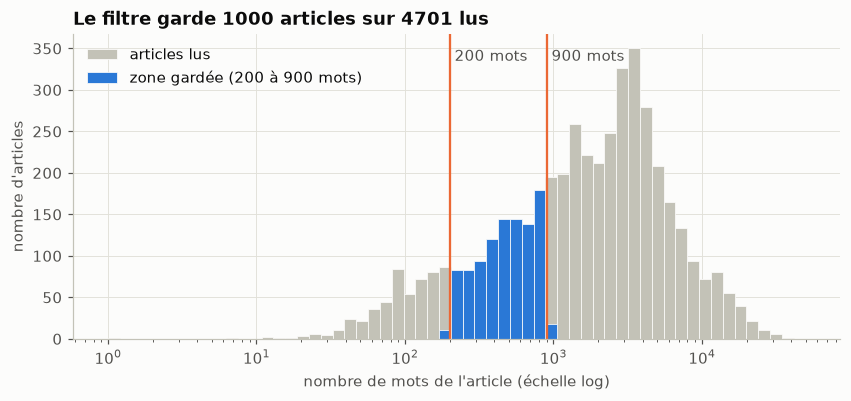

In [3]:
longueurs_lues = []          # nombre de mots de chaque article lu, gardé ou non
motifs_rejet = Counter()
n_gardes = 0

for row in load_dataset("kaitchup/wikipedia-20220301-fr-sample-10k", split="train", streaming=True):
    title = (row["title"] or "").strip()
    body = (row["text"] or "").strip()
    n_mots = len(body.split())
    longueurs_lues.append(n_mots)
    # Mêmes tests, dans le même ordre, que keep_article()
    if not title:
        motifs_rejet["titre vide"] += 1
    elif "homonymie" in title.lower():
        motifs_rejet["page d'homonymie"] += 1
    elif n_mots < 200:
        motifs_rejet["moins de 200 mots"] += 1
    elif n_mots > 900:
        motifs_rejet["plus de 900 mots"] += 1
    else:
        n_gardes += 1
        if n_gardes >= 1000:
            break

n_lus = len(longueurs_lues)
print(f"Articles lus : {n_lus}   gardés : {n_gardes} ({n_gardes / n_lus:.0%})")
for motif, n in motifs_rejet.most_common():
    print(f"  rejetés, {motif:<20}: {n:>5} ({n / n_lus:.0%} des articles lus)")

fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.logspace(np.log10(max(1, min(longueurs_lues))), np.log10(max(longueurs_lues)), 60)
ax.hist(longueurs_lues, bins=bins, color=GRIS, edgecolor="#fcfcfb", linewidth=0.5, label="articles lus")
gardes = [n for n in longueurs_lues if 200 <= n <= 900]
ax.hist(gardes, bins=bins, color=BLEU, edgecolor="#fcfcfb", linewidth=0.5, label="zone gardée (200 à 900 mots)")
for seuil in (200, 900):
    ax.axvline(seuil, color=ORANGE, linewidth=1.5)
    ax.text(seuil, ax.get_ylim()[1] * 0.95, f" {seuil} mots", color=ENCRE_2, va="top")
ax.set_xscale("log")
ax.set_xlabel("nombre de mots de l'article (échelle log)")
ax.set_ylabel("nombre d'articles")
ax.set_title(f"Le filtre garde {n_gardes} articles sur {n_lus} lus")
ax.legend(frameon=False, loc="upper left")
sauver(fig, "01_filtre_longueur")
plt.show()

### 0.2 Contrôles de base : doublons, valeurs vides, ordre du flux

In [4]:
df["mots"] = df["body"].str.split().str.len()

print("Dimensions :", df.shape)
print("Valeurs manquantes :", int(df.isna().sum().sum()))
print("doc_id dupliqués :", df["doc_id"].duplicated().sum(),
      "| titres dupliqués :", df["title"].duplicated().sum(),
      "| textes dupliqués :", df["body"].duplicated().sum())
print()
print(df[["mots", "caracteres"]].describe().round(0).T)
print()
print(f"Caractères par mot : {df['caracteres'].sum() / df['mots'].sum():.2f}")

# Le flux suit l'ordre du dump : les premières lettres des titres montrent si l'échantillon est équilibré.
initiales = df["title"].str[0].str.upper().value_counts()
print()
print("Première lettre des titres (10 plus fréquentes) :")
print((initiales.head(10) / len(df)).map("{:.0%}".format).to_string())

# Familles de pages répétitives (même gabarit, contenu en liste)
prefixes = df["title"].str.extract(r"^(\D+?)\s+\w$")[0].value_counts()
print()
print("Titres en série « préfixe + une lettre » :")
print(prefixes[prefixes > 2].to_string())

Dimensions : (1000, 6)
Valeurs manquantes : 0
doc_id dupliqués : 0 | titres dupliqués : 0 | textes dupliqués : 0

             count    mean     std     min     25%     50%     75%     max
mots        1000.0   516.0   204.0   200.0   343.0   498.0   687.0   899.0
caracteres  1000.0  3319.0  1324.0  1128.0  2181.0  3155.0  4407.0  7094.0

Caractères par mot : 6.43

Première lettre des titres (10 plus fréquentes) :
title
A    17%
L     9%
C     8%
P     7%
M     6%
S     4%
T     4%
B     4%
1     4%
G     4%

Titres en série « préfixe + une lettre » :
0
Abréviations en informatique    17


### 0.3 Ce que l'extraction du dump a supprimé

Le dump est du wikitexte converti en texte brut. Les **modèles** (`{{date|...}}`, `{{s|XX}}`, `{{lang|...}}`) disparaissent à la conversion et laissent des trous : deux espaces de suite, des parenthèses vides, « le  à ». Si une date de naissance a disparu du texte, aucun retriever ne pourra la retrouver et le LLM devra répondre « je ne sais pas ». On mesure l'ampleur du problème.

                               articles touchés  occurrences % des articles
date supprimée (« né le  à »)               110          156            11%
siècle supprimé (« du . »)                  354          664            35%
parenthèse vide « ( , ) »                   138          308            14%
double espace                               770         3488            77%

[Antoine Meillet] extrait : 'Paul Jules Antoine Meillet, né le  à Moulins (Allier) et mort le  à Châteaum'
[Arthur John Evans] extrait : 'Arthur John Evans (né le  à Nash Mills dans le Hertfordshire et mor'
[Andrew Wiles] extrait : 'Andrew John Wiles (né le  à Cambridge, Angleterre) est un mathémati'


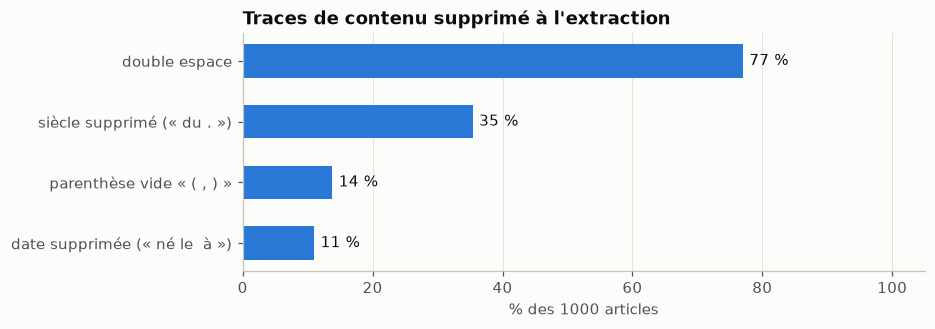

In [5]:
# Trous typiques laissés par un modèle supprimé
TROUS = {
    "date supprimée (« né le  à »)": r"\b(?:né|née|mort|morte|le)\s{2,}(?:à|en|et|,)",
    "siècle supprimé (« du . »)": r"\b(?:du|au|le|en)\s+[.,;)]",
    "parenthèse vide « ( , ) »": r"\(\s*[,;]?\s*\)|\(\s*,",
    "double espace": r"\S  \S",
}
stats = {}
for nom, motif in TROUS.items():
    n_occ = df["body"].str.count(motif)
    stats[nom] = {"articles touchés": int((n_occ > 0).sum()), "occurrences": int(n_occ.sum())}
trous = pd.DataFrame(stats).T
trous["% des articles"] = (trous["articles touchés"] / len(df)).map("{:.0%}".format)
print(trous.to_string())

# Trois exemples en contexte
print()
motif = TROUS["date supprimée (« né le  à »)"]
for body, title in df.loc[df["body"].str.contains(motif), ["body", "title"]].head(3).values:
    m = re.search(motif, body)
    print(f"[{title}] extrait : {body[max(0, m.start() - 60): m.end() + 40]!r}")

fig, ax = plt.subplots(figsize=(8, 2.8))
part = trous["articles touchés"].sort_values() / len(df) * 100
ax.barh(part.index, part.values, color=BLEU, height=0.55)
for y, v in enumerate(part.values):
    ax.text(v + 1, y, f"{v:.0f} %", va="center", color=ENCRE)
ax.set_xlim(0, 105)
ax.set_xlabel("% des 1000 articles")
ax.grid(axis="y", visible=False)
ax.set_title("Traces de contenu supprimé à l'extraction")
sauver(fig, "02_trous_extraction")
plt.show()

### 0.4 Structure du texte : paragraphes et titres de section

Le chunking récursif découpe d'abord sur `\n\n`, puis sur `\n`, puis sur `. `. On vérifie donc quels séparateurs existent, comment sont écrits les titres de section, et la longueur des paragraphes par rapport à la taille de chunk de 500 caractères.

Articles contenant \n\n : 999 / 1000
Moyenne de \n\n par article : 14.6
Moyenne de \n simples par article : 22.4

Articles avec au moins un titre de section : 985
Titres de section les plus fréquents :
   383  Liens externes
   348  Articles connexes
   194  Notes et références
   140  Bibliographie
   119  Voir aussi
   103  Histoire
    87  Événements
    81  Biographie
    55  Historique
    54  Europe
    48  Personnages significatifs
    44  Lien externe
    42  |
    36  Évènements
    32  Description



13781 paragraphes | médiane 144 caractères | 12% dépassent 500 caractères | 41% font moins de 100 caractères


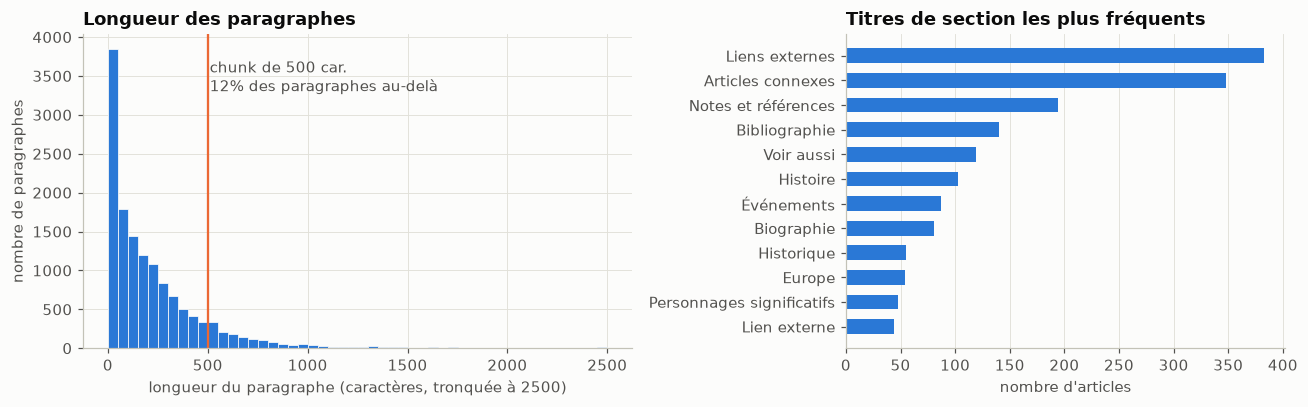

In [6]:
print("Articles contenant \\n\\n :", df["body"].str.contains("\n\n").sum(), "/", len(df))
print("Moyenne de \\n\\n par article :", round(df["body"].str.count("\n\n").mean(), 1))
print("Moyenne de \\n simples par article :", round((df["body"].str.count("\n") - 2 * df["body"].str.count("\n\n")).mean(), 1))

# Dans ce dump, un titre de section est une ligne courte terminée par « espace + \n » : « Biographie \n »
TITRE_SECTION = re.compile(r"(?m)^([^\n.!?]{2,80}?) \n")
titres_sections = Counter(t.strip() for body in df["body"] for t in TITRE_SECTION.findall(body))
df["n_sections"] = df["body"].map(lambda b: len(TITRE_SECTION.findall(b)))
print("\nArticles avec au moins un titre de section :", (df["n_sections"] > 0).sum())
print("Titres de section les plus fréquents :")
for t, n in titres_sections.most_common(15):
    print(f"  {n:>4}  {t}")

# Paragraphes = blocs séparés par une ligne vide ; on retire les titres de section en tête de bloc
paragraphes = []
for body in df["body"]:
    for bloc in body.split("\n\n"):
        bloc = TITRE_SECTION.sub("", bloc + "\n").strip()
        if bloc:
            paragraphes.append(len(bloc))
paragraphes = np.array(paragraphes)
print(f"\n{len(paragraphes)} paragraphes | médiane {np.median(paragraphes):.0f} caractères "
      f"| {np.mean(paragraphes > 500):.0%} dépassent 500 caractères "
      f"| {np.mean(paragraphes < 100):.0%} font moins de 100 caractères")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
ax.hist(np.clip(paragraphes, 0, 2500), bins=50, color=BLEU, edgecolor="#fcfcfb", linewidth=0.5)
ax.axvline(500, color=ORANGE, linewidth=1.5)
ax.text(510, ax.get_ylim()[1] * 0.92, f"chunk de 500 car.\n{np.mean(paragraphes > 500):.0%} des paragraphes au-delà", color=ENCRE_2, va="top")
ax.set_xlabel("longueur du paragraphe (caractères, tronquée à 2500)")
ax.set_ylabel("nombre de paragraphes")
ax.set_title("Longueur des paragraphes")

ax = axes[1]
top = titres_sections.most_common(12)[::-1]
ax.barh([t for t, _ in top], [n for _, n in top], color=BLEU, height=0.6)
ax.set_xlabel("nombre d'articles")
ax.grid(axis="y", visible=False)
ax.set_title("Titres de section les plus fréquents")
fig.tight_layout()
sauver(fig, "03_structure_paragraphes")
plt.show()

### 0.5 La fin des articles : sections vides ou bruitées

Les sections « Notes et références », « Liens externes », « Voir aussi » ne contiennent plus que leurs titres une fois les liens et les modèles supprimés. Un chunk fait de ces restes n'apporte rien à la recherche : on regarde la fin réelle de quelques articles et la part du texte qui se trouve après la première de ces sections.

In [7]:
SECTIONS_FIN = ["Notes et références", "Références", "Liens externes", "Voir aussi",
                "Articles connexes", "Bibliographie", "Annexes", "Notes"]
motif_fin = re.compile(r"(?m)^(?:" + "|".join(map(re.escape, SECTIONS_FIN)) + r") \n")

def part_apres_fin(body):
    m = motif_fin.search(body)
    return 0.0 if m is None else (len(body) - m.start()) / len(body)

df["part_fin"] = df["body"].map(part_apres_fin)
avec_fin = df["part_fin"] > 0
print(f"Articles avec une section de fin : {avec_fin.sum()} / {len(df)}")
print(f"Part du texte après cette section : médiane {df.loc[avec_fin, 'part_fin'].median():.1%}, "
      f"max {df['part_fin'].max():.0%}")
print()
for title, body in df[["title", "body"]].sample(3, random_state=1).values:
    print(f"[{title}] fin : {body[-220:]!r}\n")

# Le filtre « homonymie » ne regarde que le titre. Les pages d'homonymie sans ce mot dans le titre
# (« Démon », « Chou ») passent : on les repère à leur formule d'ouverture ou à leur catégorie finale.
homonymie = df["body"].str.contains(r"peut (?:désigner|faire référence)|Homonymie\s*$|Homonymie de", regex=True)
print(f"Pages d'homonymie passées à travers le filtre : {homonymie.sum()}")
print(" / ".join(df.loc[homonymie, "title"].head(12)))

Articles avec une section de fin : 829 / 1000
Part du texte après cette section : médiane 5.4%, max 62%

[Vocatif] fin : 'Michè\n Catalina → o Catalì\n Ghjacumu → o Ghjà\n\nSouvent, le vocatif corse du prénom est utilisé couramment (y compris en français) dans des cas fautifs pour désigner les personnes.\n\nSources et références \n\nCas grammatical'

[Démon] fin : "ker Demon, un avion militaire britannique de l'entre-deux-guerres.\n McDonnell F3H Demon, un avion de l'US Navy.\n Le Démon assis, tableau de Mikhaïl Vroubel (1890).\n\nNotes et références\n\nVoir aussi \n\n \n\nHomonymie de titre"

[Chou] fin : "artement du Jura\n Les Choux, commune française du département du Loiret : Démographie des Choux\n Les Choux, ensemble d'immeubles situés à Créteil\n Piéride du chou, papillon\n\n Punaise rouge du chou\n Boucles de Chou-Reggia"

Pages d'homonymie passées à travers le filtre : 48
Beaufort / Baba / Colon / Chinois / DL / FPS / Groupe / Gone / Herbe / IP / Jura / Jupiter


### 0.6 Quels types de pages ?

Une typologie grossière, à base de motifs dans le titre et la première phrase. Elle sert surtout à choisir les questions de test de la partie 3.

type
autre                 714
personne              102
liste ou glossaire     62
divinité               40
année                  40
œuvre ou groupe        25
lieu                   14
astéroïde               3


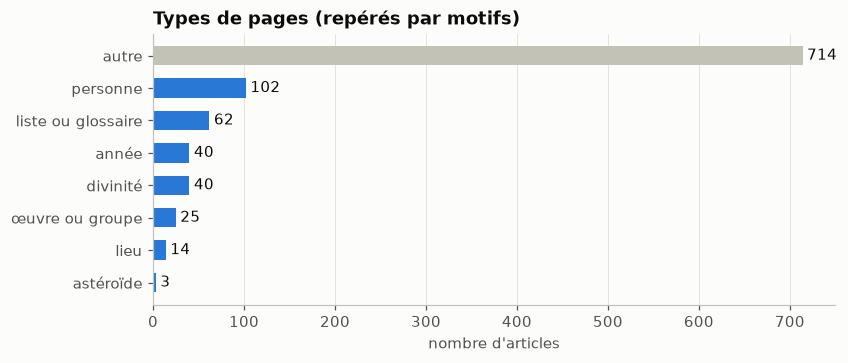

In [8]:
def type_de_page(row):
    titre, debut = row["title"], row["body"][:300].lower()
    if re.fullmatch(r"\d{1,4}", titre) or "concerne l'année" in debut:
        return "année"
    if re.match(r"(liste|abréviations|glossaire|chronologie)\b", titre.lower()):
        return "liste ou glossaire"
    if "astéroïde" in debut:
        return "astéroïde"
    if re.search(r"\best une (?:commune|ville|localité|municipalité|région|province|île)\b", debut):
        return "lieu"
    if re.search(r"\b(?:né|née)\b|\bmort le\b|\(\s*[-–]\s*\)", debut):
        return "personne"
    if re.search(r"\b(?:dieu|déesse|divinité)\b", debut):
        return "divinité"
    if re.search(r"\best (?:un|une) (?:film|album|roman|série|jeu|chanson|groupe)\b", debut):
        return "œuvre ou groupe"
    return "autre"

df["type"] = df.apply(type_de_page, axis=1)
types = df["type"].value_counts()
print(types.to_string())

fig, ax = plt.subplots(figsize=(8, 3.2))
t = types.sort_values()
ax.barh(t.index, t.values, color=[GRIS if i == "autre" else BLEU for i in t.index], height=0.6)
for y, v in enumerate(t.values):
    ax.text(v + 5, y, str(v), va="center", color=ENCRE)
ax.set_xlabel("nombre d'articles")
ax.grid(axis="y", visible=False)
ax.set_title("Types de pages (repérés par motifs)")
sauver(fig, "04_types_de_pages")
plt.show()

### 0.7 Budget de tokens : encodeur et LLM

Un modèle d'embedding **tronque** silencieusement tout ce qui dépasse sa longueur maximale : la fin du chunk n'est simplement pas encodée. On lit cette limite dans la configuration du modèle au lieu de la supposer, puis on compte les tokens d'une fenêtre de 500 caractères (avec un chevauchement de 50) sur tout le corpus. Ce n'est qu'un aperçu : le vrai découpage est l'objet de la partie 1.

sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 : max_seq_length = 128, vocabulaire = 250002


7753 fenêtres de 500 caractères (7.8 par article)
Tokens par fenêtre complète : médiane 137, 9e décile 155, max 272
Fenêtres tronquées par l'encodeur (> 128 tokens) : 65%
Caractères par token (encodeur) : 3.68


Qwen : 140 tokens par fenêtre en médiane, soit environ 820 tokens pour un prompt à 5 chunks


  fenêtre de 200 caractères : 0% tronquées
  fenêtre de 250 caractères : 0% tronquées
  fenêtre de 300 caractères : 0% tronquées
  fenêtre de 350 caractères : 2% tronquées
  fenêtre de 400 caractères : 7% tronquées
  fenêtre de 450 caractères : 34% tronquées
  fenêtre de 500 caractères : 74% tronquées
  fenêtre de 600 caractères : 100% tronquées
Plus grande taille testée avec au plus 10 % de fenêtres tronquées : 400 caractères


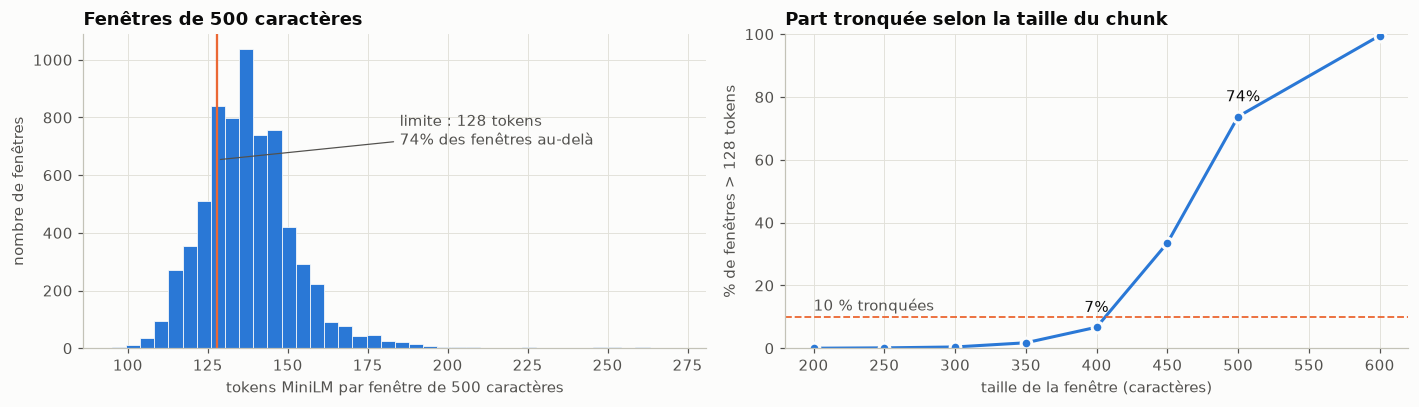

In [9]:
import json

from huggingface_hub import hf_hub_download
from transformers import AutoTokenizer

# max_seq_length est la longueur utilisée par sentence-transformers à l'encodage
config_st = json.load(open(hf_hub_download(model_encoder, "sentence_bert_config.json")))
MAX_TOKENS = config_st["max_seq_length"]
tok_enc = AutoTokenizer.from_pretrained(model_encoder)
tok_llm = AutoTokenizer.from_pretrained(model_decoder)
print(f"{model_encoder} : max_seq_length = {MAX_TOKENS}, vocabulaire = {tok_enc.vocab_size}")

# Fenêtres fixes de 500 caractères, pas de 450 (= 500 - 50 de chevauchement)
TAILLE, CHEVAUCHEMENT = 500, 50
fenetres = [body[i:i + TAILLE]
            for body in df["body"]
            for i in range(0, max(1, len(body) - CHEVAUCHEMENT), TAILLE - CHEVAUCHEMENT)]
# add_special_tokens=True compte <s> et </s>, qui occupent aussi 2 des places
n_tok = np.array([len(ids) for ids in tok_enc(fenetres, add_special_tokens=True)["input_ids"]])
n_car = np.array([len(f) for f in fenetres])
complets = n_car == TAILLE
print(f"{len(fenetres)} fenêtres de {TAILLE} caractères ({len(fenetres) / len(df):.1f} par article)")
print(f"Tokens par fenêtre complète : médiane {np.median(n_tok[complets]):.0f}, "
      f"9e décile {np.percentile(n_tok[complets], 90):.0f}, max {n_tok.max()}")
print(f"Fenêtres tronquées par l'encodeur (> {MAX_TOKENS} tokens) : {np.mean(n_tok > MAX_TOKENS):.0%}")
print(f"Caractères par token (encodeur) : {n_car.sum() / (n_tok - 2).sum():.2f}")

# Côté LLM : 5 chunks + consignes + question doivent tenir dans le contexte de Qwen (32 768 tokens)
tok_llm_fen = np.array([len(ids) for ids in tok_llm(fenetres[:2000])["input_ids"]])
print(f"Qwen : {np.median(tok_llm_fen):.0f} tokens par fenêtre en médiane, "
      f"soit environ {5 * np.median(tok_llm_fen) + 120:.0f} tokens pour un prompt à 5 chunks")

# Même mesure pour d'autres tailles de fenêtre : quelle taille tient dans les 128 tokens ?
tailles = [200, 250, 300, 350, 400, 450, 500, 600]
part_tronquee = []
for taille in tailles:
    fen = [body[i:i + taille] for body in df["body"]
           for i in range(0, len(body) - taille + 1, taille - CHEVAUCHEMENT)]   # fenêtres complètes seulement
    longueurs = np.array([len(ids) for ids in tok_enc(fen, add_special_tokens=True)["input_ids"]])
    part_tronquee.append(np.mean(longueurs > MAX_TOKENS))
for taille, p in zip(tailles, part_tronquee):
    print(f"  fenêtre de {taille} caractères : {p:.0%} tronquées")
taille_sure = max(t for t, p in zip(tailles, part_tronquee) if p <= 0.10)
print(f"Plus grande taille testée avec au plus 10 % de fenêtres tronquées : {taille_sure} caractères")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
ax.hist(n_tok[complets], bins=40, color=BLEU, edgecolor="#fcfcfb", linewidth=0.5)
ax.axvline(MAX_TOKENS, color=ORANGE, linewidth=1.5)
# Annotation placée à droite de la distribution pour ne pas recouvrir les barres
ax.annotate(f"limite : {MAX_TOKENS} tokens\n{np.mean(n_tok[complets] > MAX_TOKENS):.0%} des fenêtres au-delà",
            xy=(MAX_TOKENS, ax.get_ylim()[1] * 0.6), xytext=(185, ax.get_ylim()[1] * 0.75),
            color=ENCRE_2, va="top", arrowprops={"arrowstyle": "-", "color": ENCRE_2, "linewidth": 0.8})
ax.set_xlabel("tokens MiniLM par fenêtre de 500 caractères")
ax.set_ylabel("nombre de fenêtres")
ax.set_title("Fenêtres de 500 caractères")

ax = axes[1]
ax.plot(tailles, np.array(part_tronquee) * 100, color=BLEU, linewidth=2, marker="o", markersize=7,
        markeredgecolor="#fcfcfb", markeredgewidth=2)
ax.axhline(10, color=ORANGE, linewidth=1.2, linestyle="--")
ax.text(tailles[0], 12, "10 % tronquées", color=ENCRE_2)
for t, p in zip(tailles, part_tronquee):
    if t in (taille_sure, 500):
        ax.annotate(f"{p:.0%}", (t, p * 100), textcoords="offset points", xytext=(-8, 10), color=ENCRE)
ax.set_ylim(0, 100)
ax.set_xlabel("taille de la fenêtre (caractères)")
ax.set_ylabel("% de fenêtres > 128 tokens")
ax.set_title("Part tronquée selon la taille du chunk")
fig.tight_layout()
sauver(fig, "05_tokens_encodeur")
plt.show()

### 0.8 Carte des sujets (rappel du cours : TF-IDF, réduction de dimension, k-means)

On réutilise les outils des chapitres précédents pour voir de quoi parle l'échantillon :

- **TF-IDF** sur les articles entiers (vecteurs creux, une dimension par mot) ;
- **SVD tronquée** à 100 dimensions (analyse sémantique latente, l'équivalent de l'ACP pour une matrice creuse non centrée) ;
- **k-means** à 8 classes sur les vecteurs normalisés (donc sur la similarité cosinus, comme le *spherical k-means*) ;
- **t-SNE** pour projeter en 2D. t-SNE préserve les voisinages locaux, pas les distances globales : la position relative de deux groupes éloignés ne veut rien dire.

Avec 8 groupes, une seule couleur par groupe sur un nuage de points devient illisible. On utilise donc des petits multiples : un panneau par groupe, le groupe en bleu sur le reste du corpus en gris.

Matrice TF-IDF : (1000, 12507) | densité 1.23%


Variance expliquée par 100 composantes : 25%
 groupe  articles                                                    mots clés                                                                                      exemples
      7       291                    français, the, nom, série, manga, musique                                                  Akihabara / Arthur John Evans / Arts visuels
      6       172                   exemple, être, cas, système, peuvent, voir                                Algèbre générale / Anastylose / Lampe à incandescence halogène
      1       147      communes, liste, département, commune, état, population Alejandro Toledo / Géographie de l'Arabie saoudite / Histoire économique de l'Arabie saoudite
      2       117 logiciel, linux, logiciels, version, protocole, informatique                    Abréviations en informatique A / Port AGP / Abréviations en informatique M
      3        78            guerre, france, années, charles, peintre, espagne            

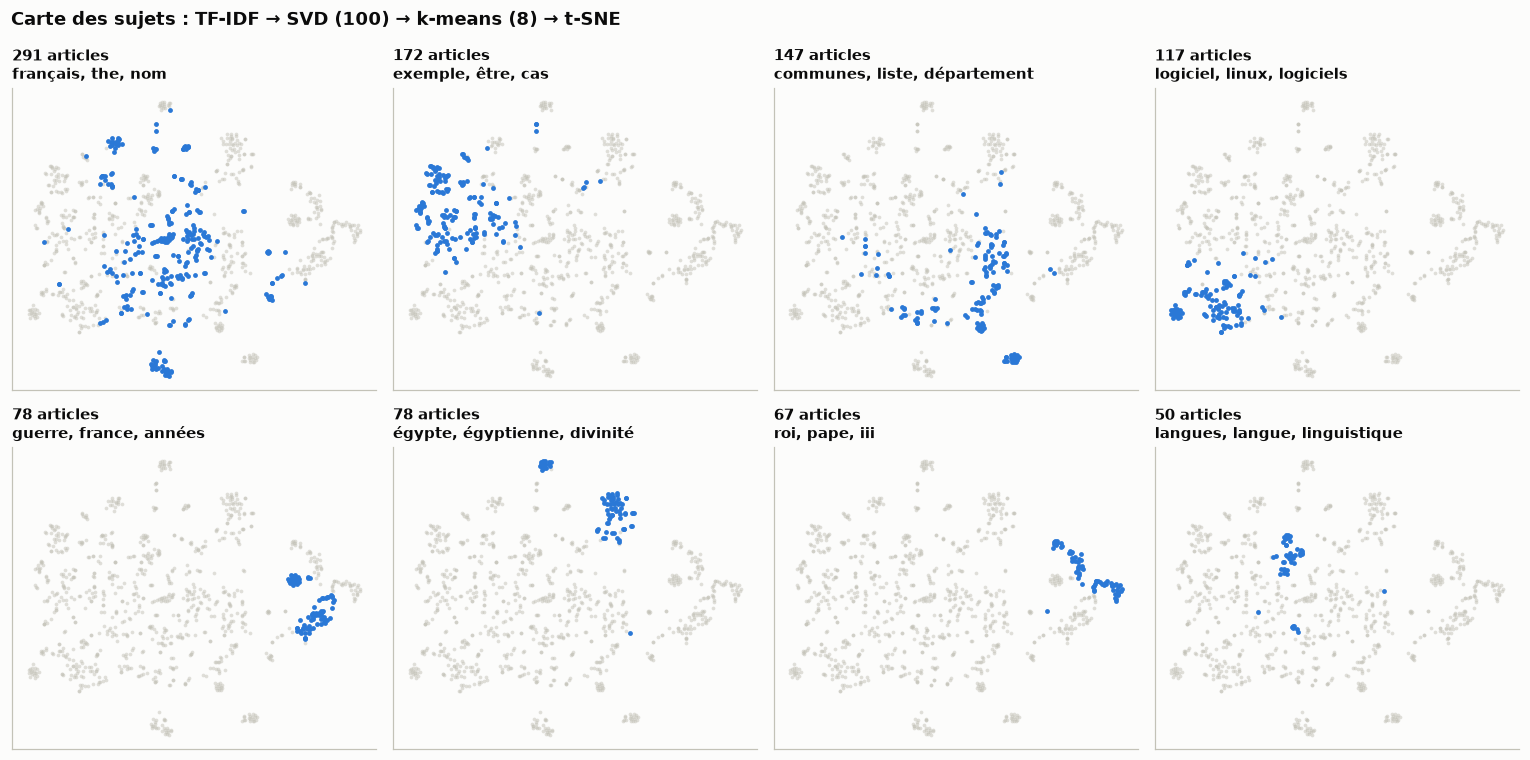

In [10]:
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize

# Mots vides français courants (scikit-learn ne fournit qu'une liste anglaise)
MOTS_VIDES_FR = set('''au aux avec ce ces dans de des du elle en et eux il ils je la le les leur lui ma mais me même mes moi mon ne nos
notre nous on ou par pas pour qu que qui sa se ses son sur ta te tes toi ton tu un une vos votre vous c d j l à m n s t y été
étée étées étés étant suis es est sommes êtes sont serai sera seront serait seraient étais était étaient fut furent soit
ai as avons avez ont aura auront avait avaient eut eurent ayant eu cette cet celle celui ceux comme plus aussi ainsi alors
après avant entre sous sans dont où lors leurs fait faire peut tout tous toute toutes autre autres deux trois très bien
encore donc car ni non oui si selon depuis vers chez contre parmi pendant puis quand tant tandis afin elles cela ceci ici'''.split())

tfidf_carte = TfidfVectorizer(
    lowercase=True,
    stop_words=sorted(MOTS_VIDES_FR),
    token_pattern=r"(?u)\b[^\W\d_]{3,}\b",   # mots d'au moins 3 lettres, sans chiffres
    min_df=3,                                  # mot présent dans au moins 3 articles
    max_df=0.5,                                # retire les mots présents dans plus de la moitié des articles
    sublinear_tf=True,                         # 1 + log(tf) : atténue les mots répétés
)
X_tfidf = tfidf_carte.fit_transform(df["body"])
print("Matrice TF-IDF :", X_tfidf.shape, f"| densité {X_tfidf.nnz / np.prod(X_tfidf.shape):.2%}")

svd = TruncatedSVD(n_components=100, random_state=0)
X_lsa = normalize(svd.fit_transform(X_tfidf))      # normalisation L2 : distance euclidienne ~ cosinus
print(f"Variance expliquée par 100 composantes : {svd.explained_variance_ratio_.sum():.0%}")

K = 8
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X_lsa)
df["groupe"] = km.labels_

# Mots les plus représentatifs d'un groupe : moyenne TF-IDF de ses articles
vocab = np.array(tfidf_carte.get_feature_names_out())
resume_groupes = []
for k in range(K):
    masque = (df["groupe"] == k).to_numpy()
    poids = np.asarray(X_tfidf[masque].mean(axis=0)).ravel()
    resume_groupes.append({
        "groupe": k, "articles": int(masque.sum()),
        "mots clés": ", ".join(vocab[poids.argsort()[::-1][:6]]),
        "exemples": " / ".join(df.loc[masque, "title"].head(3)),
    })
resume_groupes = pd.DataFrame(resume_groupes).sort_values("articles", ascending=False)
print(resume_groupes.to_string(index=False))

coords = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(X_lsa)

fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharex=True, sharey=True)
for ax, (_, g) in zip(axes.ravel(), resume_groupes.iterrows()):
    masque = (df["groupe"] == g["groupe"]).to_numpy()
    ax.scatter(coords[~masque, 0], coords[~masque, 1], s=6, color=GRIS, alpha=0.5, linewidths=0)
    ax.scatter(coords[masque, 0], coords[masque, 1], s=10, color=BLEU, linewidths=0)
    mots = g["mots clés"].split(", ")
    ax.set_title(f"{g['articles']} articles\n{', '.join(mots[:3])}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Carte des sujets : TF-IDF → SVD (100) → k-means (8) → t-SNE", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
sauver(fig, "06_carte_sujets")
plt.show()

### 0.9 Ce qu'on retient pour la suite

| Constat | Mesure | Conséquence pour le TP |
|---|---|---|
| Le filtre garde surtout des articles courts | 1 000 gardés sur 4 701 lus ; 67 % des articles lus font plus de 900 mots | Les grands sujets (pays, personnalités majeures) sont absents. Les questions de test se choisissent dans les groupes de la carte : divinités égyptiennes, linguistique, informatique, papes et rois. |
| L'échantillon suit l'ordre du dump | 17 % des titres commencent par « A » ; 17 pages « Abréviations en informatique X » | Des pages-listes au contenu pauvre, susceptibles de remonter dans le top-k sur des sigles. |
| Des pages d'homonymie passent le filtre | 48 pages repérées (Jupiter, Jura, IP, etc.), contre 44 rejetées par le titre | Elles alignent des noms propres sans rien expliquer : TF-IDF risque de les classer en tête. |
| Dates et siècles supprimés à l'extraction | 11 % des articles ont une date de naissance ou de mort vide (« né le  à »), 35 % un siècle vide (« du . ») | Une question « quand est né X ? » n'a plus de réponse dans le texte. **Correction (partie 3.4) :** pour 79 de ces 110 articles, la date survit dans les catégories de fin d'article (« Naissance en novembre 1866 »), que le nettoyage de la partie 1 supprimait ; la partie 3.5 les récupère. |
| Une vraie structure de paragraphes | `\n\n` présent dans 999 articles (14,6 par article) ; titres de section écrits « Titre \n » ; 41 % des paragraphes font moins de 100 caractères, 12 % plus de 500 | Le découpage récursif a de bons séparateurs. Il faut fusionner les petits blocs et garder le titre de section avec son paragraphe. |
| Sections de fin vides | 829 articles ont « Liens externes », « Notes et références », etc. (5 % du texte en médiane) | Des chunks sans information, à retirer avant l'indexation. |
| Limite de l'encodeur | `max_seq_length` = 128 tokens ; 3,7 caractères par token ; 74 % des fenêtres complètes de 500 caractères dépassent la limite, 7 % à 400 caractères | Au-delà de 128 tokens, la fin du chunk n'est pas encodée. On vise des chunks d'environ 400 caractères, ou on mesure la taille directement en tokens. |
| Budget du LLM | environ 140 tokens Qwen par chunk, environ 820 pour un prompt à 5 chunks | Large marge dans le contexte de Qwen2.5 (32 768 tokens) : k peut augmenter sans risque. |

## Partie 1 : découpage des documents (chunking)

**Choix des deux méthodes** : la **fenêtre fixe** (la référence simple) et le **découpage récursif** (qui suit la structure du texte). Le découpage sémantique est discuté plus bas : il demande d'encoder chaque phrase avant même d'indexer.

**Paramètres, déduits de l'étape 0** :

| | Fenêtre fixe | Récursif |
|---|---|---|
| Unité de mesure | caractères | tokens de l'encodeur MiniLM |
| Taille maximale | 400 caractères (au lieu des 500 de l'énoncé, dont 74 % dépassent 128 tokens) | 110 tokens |
| Chevauchement | 50 caractères | 15 tokens (environ 55 caractères) |

Les 110 tokens laissent une marge sous la limite de 128 : 2 tokens spéciaux (`<s>`, `</s>`) et environ 16 tokens pour préfixer le titre de l'article en partie 2.

Les deux méthodes reçoivent **le même texte nettoyé**, pour que la comparaison ne porte que sur la façon de couper.

### 1.1 Nettoyage commun (conséquences de l'étape 0)

In [11]:
from transformers import AutoTokenizer

# Sections de fin : après extraction, elles ne contiennent plus que leur titre ou des listes de liens.
SECTIONS_FIN = ["Notes et références", "Références", "Liens externes", "Lien externe", "Voir aussi",
                "Articles connexes", "Bibliographie", "Annexes", "Sources et références", "Sources", "Notes"]
# (?m)^ : début de ligne ; la ligne doit contenir exactement le titre de section (espaces de fin tolérés)
FIN_ARTICLE = re.compile(r"(?m)^(?:" + "|".join(map(re.escape, SECTIONS_FIN)) + r")[ \t]*$")

def nettoyer(body: str) -> str:
    # 1. On coupe à la première section de fin : liens, références vidées par l'extraction, catégories.
    #    Attention : certaines catégories portent des dates (« Naissance en novembre 1866 ») ;
    #    la partie 3.5 montre ce que cette coupe fait perdre et le récupère.
    m = FIN_ARTICLE.search(body)
    if m:
        body = body[:m.start()]
    # 1 bis. Catégorie résiduelle des pages d'homonymie (« Homonymie de patronyme ») en dernière ligne
    body = re.sub(r"\n+\s*Homonymie[^\n]*\s*$", "", body)
    # 2. Parenthèses vidées par la suppression des modèles {{lang|...}} : « IRA ( , ) »
    body = re.sub(r"\(\s*[,;]?\s*\)", "", body)
    # 3. Doubles espaces laissés par les dates et siècles supprimés : « né le  à » devient « né le à »
    body = re.sub(r"[ \t]{2,}", " ", body)
    # 4. Espaces en fin de ligne (les titres de section sont écrits « Biographie \n »)
    body = re.sub(r"[ \t]+\n", "\n", body)
    # 5. Au plus une ligne vide entre deux blocs, pour que « \n\n » reste LE séparateur de paragraphes
    body = re.sub(r"\n{3,}", "\n\n", body)
    return body.strip()

df["texte"] = df["body"].map(nettoyer)
retire = 1 - df["texte"].str.len().sum() / df["body"].str.len().sum()
print(f"Caractères retirés par le nettoyage : {retire:.1%}")
print(f"Articles raccourcis par la coupe de fin : {(df['texte'].str.len() < df['body'].str.len() * 0.98).sum()}")
print("\nAvant :", repr(df.loc[0, "body"][:120]))
print("Après :", repr(df.loc[0, "texte"][:120]))

# Longueur mesurée comme la mesure l'encodeur. Sans <s> et </s> : ils sont dans la marge.
tok_enc = AutoTokenizer.from_pretrained(model_encoder)

def n_tokens(texte: str) -> int:
    # verbose=False : pas d'avertissement quand on mesure un texte plus long que 512 tokens
    return len(tok_enc(texte, add_special_tokens=False, verbose=False)["input_ids"])

Caractères retirés par le nettoyage : 7.3%
Articles raccourcis par la coupe de fin : 757

Avant : 'Paul Jules Antoine Meillet, né le  à Moulins (Allier) et mort le  à Châteaumeillant (Cher), est le principal linguiste f'
Après : 'Paul Jules Antoine Meillet, né le à Moulins (Allier) et mort le à Châteaumeillant (Cher), est le principal linguiste fra'


### 1.2 Méthode 1 : fenêtre fixe

Une fenêtre de `T` caractères glisse sur le texte avec un pas de `T − O` : chaque chunk reprend les `O` derniers caractères du précédent. Pour un texte de `L` caractères, on obtient `1 + ⌈(L − T) / (T − O)⌉` chunks, et le texte est stocké environ `T / (T − O)` fois.

Les fonctions renvoient des **positions** `(début, fin)` et non des chaînes : cela permet de retrouver le contexte d'un chunk, de mesurer s'il coupe un mot, et de surligner le chevauchement.

In [12]:
TAILLE_FIXE = 400          # caractères ; 500 dans l'énoncé, mais 74 % des fenêtres de 500 dépassent 128 tokens
CHEVAUCHEMENT_FIXE = 50    # caractères repris du chunk précédent

def decoupe_fixe(texte: str, taille: int = TAILLE_FIXE, chevauchement: int = CHEVAUCHEMENT_FIXE):
    assert 0 <= chevauchement < taille, "le chevauchement doit être plus petit que la fenêtre"
    pas = taille - chevauchement
    bornes, debut = [], 0
    while True:
        fin = min(debut + taille, len(texte))
        bornes.append((debut, fin))
        # On s'arrête dès qu'une fenêtre touche la fin : sinon la dernière ne contiendrait que du chevauchement.
        if fin == len(texte):
            return bornes
        debut += pas

texte_ex = df.loc[0, "texte"]
bornes_ex = decoupe_fixe(texte_ex)
print(f"« {df.loc[0, 'title']} » : {len(texte_ex)} caractères, {len(bornes_ex)} chunks "
      f"(formule : {1 + math.ceil(max(0, len(texte_ex) - TAILLE_FIXE) / (TAILLE_FIXE - CHEVAUCHEMENT_FIXE))})")
for d, f in bornes_ex[:3]:
    print(f"[{d:>4}, {f:>4})  {texte_ex[d:f][:70]!r} / {texte_ex[d:f][-40:]!r}")

« Antoine Meillet » : 5343 caractères, 16 chunks (formule : 16)
[   0,  400)  'Paul Jules Antoine Meillet, né le à Moulins (Allier) et mort le à Chât' / ' de Paris à partir de 1885 où il suit no'
[ 350,  750)  'es lettres de Paris à partir de 1885 où il suit notamment les cours de' / ' 1894 par une conférence sur les langues'
[ 700, 1100)  ' partir de 1894 par une conférence sur les langues persanes.\n\nEn 1897,' / 'uiste Auguste Carrière à la tête de la c'


### 1.3 Méthode 2 : découpage récursif

L'algorithme essaie d'abord le séparateur le plus « gros » :

1. Si le texte tient dans 110 tokens, c'est un chunk.
2. Sinon, on le coupe sur le premier séparateur présent, dans l'ordre `\n\n` (paragraphes), `\n` (titres de section, éléments de liste), `". "` (phrases), `" "` (mots).
3. Les morceaux assez petits sont mis de côté ; un morceau trop gros est redécoupé **récursivement** avec le séparateur suivant.
4. Les morceaux mis de côté sont **fusionnés** de gauche à droite tant que leur total tient dans 110 tokens. Quand un chunk est plein, le suivant repart avec les derniers morceaux du précédent, dans la limite de 15 tokens : c'est le chevauchement, qui se fait ici sur des phrases entières.

Le séparateur reste collé à la fin du morceau, si bien que `"".join(morceaux) == texte` : un chunk est toujours un extrait exact du texte.

In [13]:
MAX_TOKENS_CHUNK = 110        # + 2 tokens spéciaux + ~16 tokens pour un titre en préfixe < 128
CHEVAUCHEMENT_TOKENS = 15     # environ 55 caractères, comparable aux 50 caractères de la méthode fixe
SEPARATEURS = ["\n\n", "\n", ". ", " "]   # paragraphe, ligne, phrase, mot

def couper_en_gardant(texte: str, sep: str):
    # (?<=sep) : on coupe juste APRÈS chaque séparateur, qui reste donc à la fin du morceau
    return [m for m in re.split(f"(?<={re.escape(sep)})", texte) if m]

def fusionner(morceaux, max_tokens, chevauchement):
    chunks, courant = [], []
    for m in morceaux:
        if courant and n_tokens("".join(courant) + m) > max_tokens:
            chunks.append("".join(courant))
            # Chevauchement : on retire les morceaux du début du chunk émis jusqu'à ce qu'il en reste
            # au plus `chevauchement` tokens, et qu'il y ait de la place pour le nouveau morceau.
            while courant and (n_tokens("".join(courant)) > chevauchement
                               or n_tokens("".join(courant) + m) > max_tokens):
                courant.pop(0)
        courant.append(m)
    if courant:
        chunks.append("".join(courant))
    return chunks

def decoupe_recursive(texte, max_tokens=MAX_TOKENS_CHUNK, chevauchement=CHEVAUCHEMENT_TOKENS, separateurs=SEPARATEURS):
    if n_tokens(texte) <= max_tokens:
        return [texte]
    # Premier séparateur (le plus gros) effectivement présent dans ce texte
    niveau = next((i for i, s in enumerate(separateurs) if s in texte), None)
    if niveau is None:
        # Plus aucun séparateur (un « mot » de plus de 110 tokens) : coupe brute, cas pathologique
        return [texte[i:i + 300] for i in range(0, len(texte), 300)]
    sep, plus_fins = separateurs[niveau], separateurs[niveau + 1:]

    chunks, en_attente = [], []
    for m in couper_en_gardant(texte, sep):
        if n_tokens(m) <= max_tokens:
            en_attente.append(m)                     # assez petit : sera fusionné avec ses voisins
        else:
            chunks += fusionner(en_attente, max_tokens, chevauchement)   # on vide d'abord ce qui précède,
            en_attente = []                                              # pour garder l'ordre du texte
            chunks += decoupe_recursive(m, max_tokens, chevauchement, plus_fins)   # niveau inférieur
    chunks += fusionner(en_attente, max_tokens, chevauchement)
    return chunks

def decoupe_recursive_bornes(texte: str):
    # Même format que decoupe_fixe : positions (début, fin) dans le texte
    bornes, curseur = [], 0
    for c in decoupe_recursive(texte):
        c = c.strip()                        # le séparateur en fin de chunk n'apporte rien
        if not c:
            continue
        debut = texte.find(c, curseur)       # le chunk suivant commence après le début du précédent
        assert debut >= 0, "un chunk doit être un extrait exact du texte"
        bornes.append((debut, debut + len(c)))
        curseur = debut + 1
    return bornes

bornes_ex = decoupe_recursive_bornes(texte_ex)
print(f"« {df.loc[0, 'title']} » : {len(bornes_ex)} chunks récursifs")
for d, f in bornes_ex[:3]:
    print(f"[{d:>4}, {f:>4})  {n_tokens(texte_ex[d:f]):>3} tokens  {texte_ex[d:f][:70]!r} / {texte_ex[d:f][-40:]!r}")

« Antoine Meillet » : 20 chunks récursifs
[   0,  325)   89 tokens  'Paul Jules Antoine Meillet, né le à Moulins (Allier) et mort le à Chât' / ' études secondaires au lycée de Moulins.'
[ 327,  617)   78 tokens  'Étudiant à la faculté des lettres de Paris à partir de 1885 où il suit' / " est major de l'agrégation de grammaire."
[ 619,  760)   36 tokens  "Il assure à la suite de Saussure le cours de grammaire comparée, qu'il" / 'une conférence sur les langues persanes.'


### 1.4 Structure de données : une liste de dictionnaires

Chaque chunk garde l'identifiant, le titre et l'URL de son article : en partie 3, on pourra citer la source de la réponse. `debut` et `fin` permettent de revenir au texte complet autour d'un chunk.

In [14]:
import time

CODES = {"fixe": "fix", "recursif": "rec", "recursif_rattache": "rra"}   # pour des chunk_id courts et uniques

def construire_chunks(df, methode: str, decoupe):
    # decoupe : fonction texte -> liste de (début, fin)
    chunks = []
    for doc in df.itertuples(index=False):
        bornes = decoupe(doc.texte)
        for i, (debut, fin) in enumerate(bornes):
            chunks.append({
                "chunk_id": f"{doc.doc_id}-{CODES[methode]}-{i:03d}",   # unique et lisible
                "doc_id": doc.doc_id,
                "title": doc.title,
                "url": doc.url,
                "methode": methode,
                "position": i,                    # rang du chunk dans son article
                "n_chunks_doc": len(bornes),
                "debut": debut,
                "fin": fin,
                "text": doc.texte[debut:fin],
            })
    # Tokens comptés en un seul appel (bien plus rapide qu'un appel par chunk).
    # Avec <s> et </s> : c'est exactement la longueur que verra l'encodeur.
    ids = tok_enc([c["text"] for c in chunks], add_special_tokens=True, verbose=False)["input_ids"]
    for c, i in zip(chunks, ids):
        c["n_car"], c["n_tokens"] = len(c["text"]), len(i)
    return chunks

t0 = time.perf_counter(); chunks_fixe = construire_chunks(df, "fixe", decoupe_fixe); t_fixe = time.perf_counter() - t0
t0 = time.perf_counter(); chunks_rec = construire_chunks(df, "recursif", decoupe_recursive_bornes); t_rec = time.perf_counter() - t0
print(f"fixe     : {len(chunks_fixe):>5} chunks en {t_fixe:.1f} s")
print(f"récursif : {len(chunks_rec):>5} chunks en {t_rec:.1f} s")
print()
print(json.dumps({k: v for k, v in chunks_rec[1].items()}, ensure_ascii=False, indent=1)[:600])

fixe     :  9156 chunks en 1.0 s
récursif : 11861 chunks en 31.7 s

{
 "chunk_id": "3-rec-001",
 "doc_id": "3",
 "title": "Antoine Meillet",
 "url": "https://fr.wikipedia.org/wiki/Antoine%20Meillet",
 "methode": "recursif",
 "position": 1,
 "n_chunks_doc": 20,
 "debut": 327,
 "fin": 617,
 "text": "Étudiant à la faculté des lettres de Paris à partir de 1885 où il suit notamment les cours de Louis Havet, il assiste également à ceux de Michel Bréal au Collège de France et de Ferdinand de Saussure à l'École pratique des hautes études.\n\nEn 1889, il est major de l'agrégation de grammaire.",
 "n_car": 290,
 "n_tokens": 80
}


### 1.5 Vérification avec `langchain-text-splitters`

`RecursiveCharacterTextSplitter` implémente le même algorithme. Avec les mêmes séparateurs, la même mesure en tokens et le même chevauchement, il doit donner des chunks très proches : c'est un test de notre implémentation.

In [15]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter.from_huggingface_tokenizer(
    tok_enc,
    chunk_size=MAX_TOKENS_CHUNK,
    chunk_overlap=CHEVAUCHEMENT_TOKENS,
    separators=SEPARATEURS,
    keep_separator="end",      # séparateur collé à la fin du morceau, comme chez nous
)
chunks_lc = [c for t in df["texte"] for c in splitter.split_text(t)]
tok_lc = [len(i) for i in tok_enc(chunks_lc, add_special_tokens=True, verbose=False)["input_ids"]]
nos_textes = {c["text"] for c in chunks_rec}
print(f"langchain : {len(chunks_lc)} chunks | nous : {len(chunks_rec)}")
print(f"tokens médians : langchain {np.median(tok_lc):.0f} | nous {np.median([c['n_tokens'] for c in chunks_rec]):.0f}")
print(f"chunks langchain identiques à l'un des nôtres : {np.mean([c.strip() in nos_textes for c in chunks_lc]):.0%}")

langchain : 11861 chunks | nous : 11861
tokens médians : langchain 80 | nous 80
chunks langchain identiques à l'un des nôtres : 100%


### 1.6 Amélioration : rattacher les fragments

En inspectant les chunks récursifs les plus courts, on voit surtout des **titres de section orphelins** (« Histoire », « Biographie », « Résumé ») et des phrases isolées. Ce comportement vient de l'algorithme lui-même, et `langchain` fait pareil : quand un paragraphe est trop long et doit être redécoupé, les petits morceaux qui le précèdent sont émis seuls, sans attendre la suite.

Un chunk « Histoire » ne contient aucune information, mais il pose problème en partie 2. Avec un seul mot, son vecteur TF-IDF normé vaut 1 sur ce mot : il obtient un cosinus élevé avec toute question qui contient « histoire ».

Correction : un chunk de moins de 30 tokens est fusionné avec le chunk **suivant** (pour qu'un titre rejoigne le texte qu'il annonce), ou avec le précédent s'il est le dernier de l'article, à condition que l'union tienne dans 110 tokens.

In [16]:
MIN_TOKENS_CHUNK = 30

frag = [c for c in chunks_rec if c["n_car"] < 100]
print(f"Fragments récursifs (< 100 caractères) : {len(frag)} / {len(chunks_rec)}")
une_ligne = np.mean([c["text"].count("\n") == 0 for c in frag])
print(f"  dont une seule ligne : {une_ligne:.0%}")
print("  exemples :", " | ".join(repr(c["text"][:40]) for c in frag[:10:2]))

def rattacher_fragments(texte, bornes, min_tokens=MIN_TOKENS_CHUNK, max_tokens=MAX_TOKENS_CHUNK):
    bornes = list(bornes)
    i = 0
    while i < len(bornes):
        d, f = bornes[i]
        if len(bornes) > 1 and n_tokens(texte[d:f]) < min_tokens:
            for j in (i + 1, i - 1):                      # d'abord le suivant, sinon le précédent
                if 0 <= j < len(bornes):
                    a, b = min(d, bornes[j][0]), max(f, bornes[j][1])
                    if n_tokens(texte[a:b]) <= max_tokens:
                        bornes[min(i, j)] = (a, b)        # les positions suffisent : l'union est l'intervalle [a, b)
                        del bornes[max(i, j)]
                        i = min(i, j) - 1                 # on re-teste le chunk fusionné, qui peut rester petit
                        break
        i += 1
    return bornes

def decoupe_recursive_rattachee(texte):
    return rattacher_fragments(texte, decoupe_recursive_bornes(texte))

t0 = time.perf_counter()
chunks_rra = construire_chunks(df, "recursif_rattache", decoupe_recursive_rattachee)
print(f"\nrécursif + rattachement : {len(chunks_rra)} chunks en {time.perf_counter() - t0:.1f} s "
      f"| fragments restants : {sum(c['n_car'] < 100 for c in chunks_rra)}")

Fragments récursifs (< 100 caractères) : 1237 / 11861
  dont une seule ligne : 81%
  exemples : 'Études homériques' | "Généalogie de l'Irish Republican Army" | 'MVC : Modèle-vue-contrôleur\n MX : Mail e' | 'Dans le monde divin, il tient le compte ' | 'I'



récursif + rattachement : 10926 chunks en 35.0 s | fragments restants : 334


### 1.7 Comparaison chiffrée

Pour chaque chunk, on regarde :

- **taille** en caractères et en tokens, et la part **tronquée** par l'encodeur (plus de 128 tokens) ;
- **fragments** : chunks de moins de 100 caractères, trop courts pour porter une information ;
- **début propre** : le chunk commence au début d'un paragraphe, d'une ligne ou d'une phrase ;
- **fin propre** : il se termine sur une fin de phrase, de ligne ou d'article ;
- **mot coupé** : le chunk commence ou finit au milieu d'un mot ;
- **redondance** : nombre total de caractères indexés rapporté au corpus (effet du chevauchement).

In [17]:
textes = dict(zip(df["doc_id"], df["texte"]))

def qualite(c):
    t, d, f = textes[c["doc_id"]], c["debut"], c["fin"]
    avant = t[:d].rstrip(" ")
    return {
        "debut_propre": d == 0 or avant.endswith(("\n", ".", "!", "?")),
        "fin_propre": f == len(t) or t[f - 1] in ".!?" or t[f:].lstrip(" ").startswith("\n"),
        "mot_coupe": (d > 0 and t[d - 1].isalnum() and t[d].isalnum())
                     or (f < len(t) and t[f - 1].isalnum() and t[f].isalnum()),
        "tronque": c["n_tokens"] > 128,
        "fragment": c["n_car"] < 100,
    }

tous = chunks_fixe + chunks_rec + chunks_rra
df_chunks = pd.concat([pd.DataFrame(tous), pd.DataFrame([qualite(c) for c in tous])], axis=1)

total_car = df["texte"].str.len().sum()
comparaison = df_chunks.groupby("methode").agg(
    chunks=("chunk_id", "size"),
    car_median=("n_car", "median"),
    tokens_median=("n_tokens", "median"),
    tokens_max=("n_tokens", "max"),
    pct_tronques=("tronque", "mean"),
    pct_fragments=("fragment", "mean"),
    pct_debut_propre=("debut_propre", "mean"),
    pct_fin_propre=("fin_propre", "mean"),
    pct_mot_coupe=("mot_coupe", "mean"),
    car_indexes=("n_car", "sum"),
).T
comparaison.loc["chunks_par_article"] = comparaison.loc["chunks"] / len(df)
comparaison.loc["redondance"] = comparaison.loc["car_indexes"] / total_car
comparaison = comparaison.drop(index="car_indexes")[["fixe", "recursif", "recursif_rattache"]]
affichage = comparaison.astype(object)
for ligne in affichage.index:
    if ligne.startswith("pct_"):
        affichage.loc[ligne] = comparaison.loc[ligne].map("{:.0%}".format)
    elif ligne in ("chunks_par_article", "redondance"):
        affichage.loc[ligne] = comparaison.loc[ligne].map("{:.2f}".format)
    else:
        affichage.loc[ligne] = comparaison.loc[ligne].map("{:.0f}".format)
print(affichage.to_string())

methode             fixe recursif recursif_rattache
chunks              9156    11861             10926
car_median           400      280               296
tokens_median        109       80                85
tokens_max           232      112               112
pct_tronques          7%       0%                0%
pct_fragments         2%      10%                3%
pct_debut_propre     14%      99%               99%
pct_fin_propre       12%      99%               99%
pct_mot_coupe        82%       0%                0%
chunks_par_article  9.16    11.86             10.93
redondance          1.13     1.01              1.01


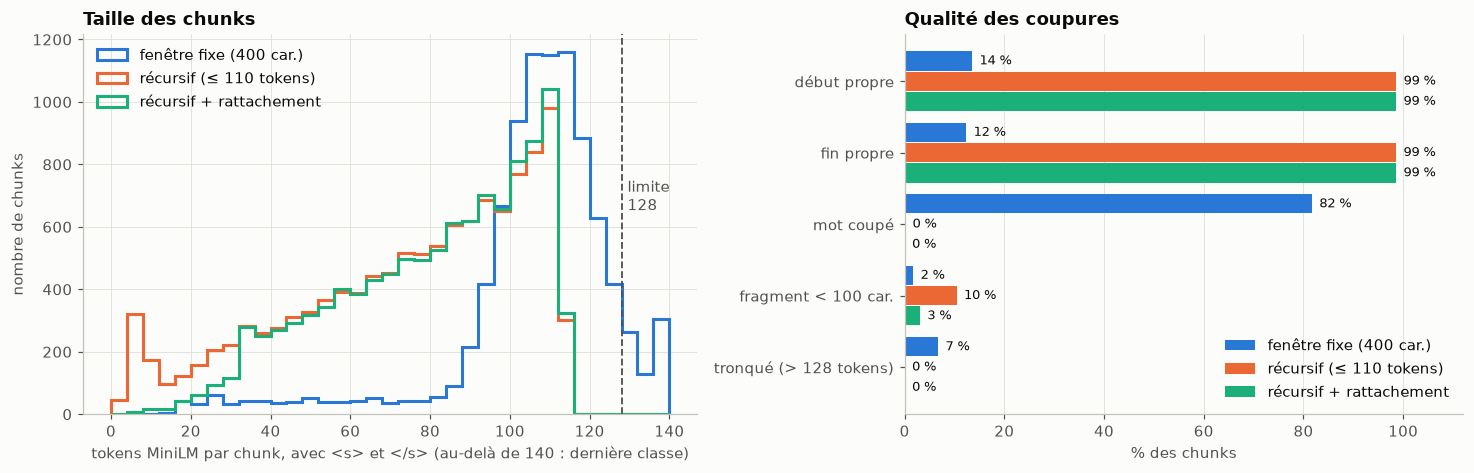

In [18]:
# Une couleur par méthode, dans l'ordre fixe de la palette, la même dans toutes les figures de la partie 1.
# Les seuils passent en tirets gris foncé pour ne pas se confondre avec la 2e méthode.
COULEURS = {"fixe": "#2a78d6", "recursif": "#eb6834", "recursif_rattache": "#1baf7a"}
NOMS = {"fixe": "fenêtre fixe (400 car.)", "recursif": "récursif (≤ 110 tokens)",
        "recursif_rattache": "récursif + rattachement"}

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4), gridspec_kw={"width_ratios": [1.1, 1]})

ax = axes[0]
bins = np.arange(0, 141, 4)
for m, couleur in COULEURS.items():
    # les rares chunks de plus de 140 tokens sont regroupés dans la dernière classe au lieu de disparaître
    v = df_chunks.loc[df_chunks["methode"] == m, "n_tokens"].clip(upper=139)
    ax.hist(v, bins=bins, histtype="step", linewidth=2, color=couleur, label=NOMS[m])
ax.axvline(128, color=ENCRE_2, linewidth=1.2, linestyle="--")
ax.text(129.5, ax.get_ylim()[1] * 0.62, "limite\n128", color=ENCRE_2, ha="left", va="top")
ax.set_xlabel("tokens MiniLM par chunk, avec <s> et </s> (au-delà de 140 : dernière classe)")
ax.set_ylabel("nombre de chunks")
ax.set_title("Taille des chunks")
ax.legend(frameon=False, loc="upper left")

ax = axes[1]
indicateurs = [("pct_debut_propre", "début propre"), ("pct_fin_propre", "fin propre"),
               ("pct_mot_coupe", "mot coupé"), ("pct_fragments", "fragment < 100 car."),
               ("pct_tronques", "tronqué (> 128 tokens)")]
y = np.arange(len(indicateurs))[::-1] * 1.2
h = 0.32
for decal, (m, couleur) in zip((h + 0.02, 0, -h - 0.02), COULEURS.items()):
    vals = [comparaison.loc[k, m] * 100 for k, _ in indicateurs]
    ax.barh(y + decal, vals, height=h, color=couleur, label=NOMS[m])
    for yy, v in zip(y + decal, vals):
        ax.text(v + 1.5, yy, f"{v:.0f} %", va="center", fontsize=8.5, color=ENCRE)
ax.set_yticks(y, [nom for _, nom in indicateurs])
ax.set_xlim(0, 112)
ax.set_xlabel("% des chunks")
ax.grid(axis="y", visible=False)
ax.set_title("Qualité des coupures")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
sauver(fig, "07_comparaison_chunking")
plt.show()

### 1.8 Comparaison visuelle, côte à côte

Le même article découpé par les trois variantes. Chaque bloc est un chunk ; la partie **surlignée** au début d'un bloc est le chevauchement, c'est-à-dire le texte déjà présent dans le chunk précédent. Le badge orange signale un chunk qui dépasse 128 tokens.

In [19]:
import html
from IPython.display import HTML, display

CSS_CHUNKS = '''
.cmp { font-family: system-ui, -apple-system, "Segoe UI", sans-serif; color: #0b0b0b; background: #fcfcfb; padding: 12px; }
.cmp h3 { margin: 18px 0 8px; font-size: 16px; }
.cmp .cols { display: grid; grid-template-columns: repeat(3, minmax(0, 1fr)); gap: 14px; }
@media (max-width: 900px) { .cmp .cols { grid-template-columns: 1fr; } }
.cmp .col h4 { margin: 0 0 8px; font-size: 13px; color: #52514e; }
.cmp .chunk { border-left: 4px solid var(--c); background: #ffffff; border-radius: 6px; padding: 8px 10px;
              margin-bottom: 8px; font-size: 12.5px; line-height: 1.45; white-space: pre-wrap; box-shadow: 0 0 0 1px rgba(11,11,11,.08); }
.cmp .meta { font-size: 11px; color: #52514e; margin-bottom: 4px; white-space: normal; }
.cmp .over { background: #f3e3b0; }
.cmp .badge { background: #eb6834; color: #fff; border-radius: 8px; padding: 0 6px; margin-left: 6px; }
'''

def colonne(doc_id, methode, couleur):
    t = textes[doc_id]
    sel = df_chunks[(df_chunks["doc_id"] == doc_id) & (df_chunks["methode"] == methode)].sort_values("position")
    blocs, fin_prec = [], 0
    for c in sel.itertuples():
        recouvre = max(0, min(fin_prec, c.fin) - c.debut) if c.position > 0 else 0
        texte_html = f'<span class="over">{html.escape(t[c.debut:c.debut + recouvre])}</span>' + html.escape(t[c.debut + recouvre:c.fin])
        badge = '<span class="badge">tronqué</span>' if c.n_tokens > 128 else ""
        blocs.append(f'<div class="chunk" style="--c:{couleur}"><div class="meta">chunk {c.position} / '
                     f'{c.n_car} car. / {c.n_tokens} tokens{badge}</div>{texte_html}</div>')
        fin_prec = c.fin
    return f'<div class="col"><h4>{NOMS[methode]} : {len(sel)} chunks</h4>{"".join(blocs)}</div>'

def cote_a_cote(titre):
    doc_id = df.loc[df["title"] == titre, "doc_id"].iloc[0]
    cols = "".join(colonne(doc_id, m, c) for m, c in COULEURS.items())
    return f'<h3>{html.escape(titre)}</h3><div class="cols">{cols}</div>'

ARTICLES_EXEMPLES = ["Antoine Meillet", "Atoum"]
corps = "".join(cote_a_cote(t) for t in ARTICLES_EXEMPLES)
display(HTML(f"<style>{CSS_CHUNKS}</style><div class='cmp'>{corps}</div>"))

# Même rendu en page autonome, pour l'ouvrir dans un navigateur
(FIG_DIR / "08_chunks_cote_a_cote.html").write_text(
    "<!doctype html><html lang='fr'><head><meta charset='utf-8'>"
    "<meta name='viewport' content='width=device-width, initial-scale=1'><title>Chunks côte à côte</title>"
    f"<style>body{{margin:0;background:#fcfcfb}}{CSS_CHUNKS}</style></head><body><div class='cmp'>{corps}</div></body></html>",
    encoding="utf-8")

41727

In [20]:
# Version texte : trois chunks consécutifs du milieu d'un article, pour chaque méthode
def montrer(titre, methode, a_partir_de=2, n=3):
    sel = df_chunks[(df_chunks["title"] == titre) & (df_chunks["methode"] == methode)].sort_values("position")
    print(f"===== {titre} / {NOMS[methode]}")
    for c in sel.iloc[a_partir_de:a_partir_de + n].itertuples():
        print(f"--- chunk {c.position} ({c.n_car} car., {c.n_tokens} tokens)")
        print(c.text)
    print()

montrer("Antoine Meillet", "fixe")
montrer("Antoine Meillet", "recursif")
montrer("Antoine Meillet", "recursif_rattache")

# Les chunks retenus pour la partie 2 : une liste de dictionnaires
chunks = chunks_rra
print(f"Chunks retenus pour l'indexation : {len(chunks)} (méthode « {chunks[0]['methode']} »)")

===== Antoine Meillet / fenêtre fixe (400 car.)
--- chunk 2 (400 car., 117 tokens)
 partir de 1894 par une conférence sur les langues persanes.

En 1897, il soutient sa thèse pour le doctorat ès lettres (Recherches sur l'emploi du génitif-accusatif en vieux-slave). En 1905, il occupe la chaire de grammaire comparée au Collège de France, où il consacre ses cours à l'histoire et à la structure des langues indo-européennes. Il succéda au linguiste Auguste Carrière à la tête de la c
--- chunk 3 (400 car., 113 tokens)
da au linguiste Auguste Carrière à la tête de la chaire d'arménien à l'École des langues orientales.

Secrétaire de la Société de linguistique de Paris, il est élu à l'Académie des inscriptions et belles-lettres en 1924. Il préside également l'Institut d'Études Slaves de 1921 à sa mort.

Il a formé toute une génération de linguistes français, parmi lesquels Émile Benveniste, Marcel Cohen, Georges 
--- chunk 4 (400 car., 109 tokens)
 lesquels Émile Benveniste, Marcel Cohen, Geo

### 1.9 Réponse à la question 3 : quelle méthode pour des articles Wikipédia ?

**Taille.** La fenêtre fixe produit des chunks presque tous identiques : 400 caractères, 109 tokens en médiane, mais jusqu'à 232 tokens sur les restes de tableaux wiki (`|-`, `! scope="col" |`) et les parties d'échecs notées coup par coup (« 14. Ch2? d5 15. Df3 »). Résultat : 7 % restent tronqués par l'encodeur, car une taille en caractères ne garantit pas une taille en tokens. Le découpage récursif produit des chunks plus courts et plus variables (85 tokens en médiane, 112 au maximum) et n'en tronque aucun, puisqu'il mesure directement en tokens.

**Cohérence.** C'est la vraie différence. La fenêtre fixe coupe un mot dans 82 % des chunks (un chunk finit par « à la tête de la c », le suivant commence par « da au linguiste ») et ne commence proprement que 14 % du temps. Le récursif commence et finit proprement dans 99 % des cas : un chunk est un paragraphe, ou un groupe de phrases entières d'un même paragraphe. Sur « Antoine Meillet », chaque chunk récursif se lit seul ; les chunks fixes demandent le précédent pour être compris.

**Verdict : le découpage récursif**, dans sa variante avec rattachement des fragments. Un article Wikipédia est déjà découpé par ses auteurs : 14,6 paragraphes en moyenne, chacun centré sur un sous-sujet. Le récursif réutilise ce découpage au lieu de l'ignorer.

**Ce qu'il ne règle pas**, et qui reste à traiter en partie 2 :

- **Les pronoms** : « Il succéda au linguiste Auguste Carrière » ne contient pas « Meillet ». On préfixera chaque chunk par le titre de son article avant de l'indexer (c'est la marge de 16 tokens prévue).
- **Le chevauchement de 15 tokens ne sert presque jamais** (redondance 1,01) : il porte sur des morceaux entiers, et une phrase dépasse presque toujours 15 tokens.
- **Plus de chunks** : 10 926 contre 9 156 (+19 %), donc un index un peu plus gros.
- **Les restes de tableaux wiki** (`|-`, `| Amon`) passent le nettoyage et forment des chunks illisibles ; on pourrait supprimer les lignes faites uniquement de balises de tableau.
- **Le séparateur « . »** coupe aussi après une abréviation (« av. J.-C. », « M. Dupont ») : la coupure tombe parfois au milieu d'une phrase, mais rarement, puisqu'il faut en plus qu'une limite de chunk tombe à cet endroit.

**Et le découpage sémantique ?** Il faudrait encoder chacun des quelque 38 000 segments du corpus (phrases et lignes), puis couper là où deux phrases voisines deviennent dissemblables. Sur Wikipédia, ces ruptures de sujet coïncident en grande partie avec les paragraphes, que le récursif exploite déjà gratuitement. Le gain attendu est faible pour un coût bien plus élevé, et il faudrait tout de même borner la taille à 128 tokens.

## Partie 2 : indexation et recherche de l'information (retrieval)

On indexe les 10 926 chunks retenus en partie 1, deux fois :

- **TF-IDF** : un vecteur creux par chunk, une dimension par mot du vocabulaire ;
- **dense** : un vecteur de 384 dimensions par chunk, produit par MiniLM.

Dans les deux cas, la pertinence est la **similarité cosinus** entre la question et le chunk, et la recherche est un **k plus proches voisins exhaustif** : on calcule le score des N chunks et on garde les k meilleurs. Avec N proche de 11 000, ce parcours complet prend quelques millisecondes ; un KD-tree ou un LSH ne serait utile qu'à une autre échelle.

**Texte indexé = « titre de l'article : texte du chunk ».** Un chunk du milieu comme « Il succéda au linguiste Auguste Carrière » ne contient pas « Meillet ». Le préfixe lui rend son sujet ; la section 2.4 mesure ce que ce choix rapporte.

In [21]:
def texte_indexe(c, avec_titre=True):
    return f"{c['title']} : {c['text']}" if avec_titre else c["text"]

textes_index = [texte_indexe(c) for c in chunks]

# Le préfixe consomme une partie de la marge de 16 tokens prévue en partie 1 : on vérifie la limite de 128.
n_tok_index = np.array([len(i) for i in tok_enc(textes_index, verbose=False)["input_ids"]])
print(f"{len(textes_index)} textes à indexer | tokens : médiane {np.median(n_tok_index):.0f}, max {n_tok_index.max()}")
print(f"Tronqués par l'encodeur malgré le préfixe (> 128 tokens) : {np.mean(n_tok_index > 128):.1%}")
print("Exemple :", repr(textes_index[3][:150]))

def afficher(resultats, largeur=110):
    # Tableau lisible : rang, score, article, début du chunk
    return pd.DataFrame([{"rang": r["rang"], "score": round(r["score"], 3), "article": r["title"],
                          "extrait": r["text"][:largeur].replace("\n", " ")} for r in resultats])

def top_k(scores, k, base=None):
    # base : la liste de chunks indexée (par défaut celle de la partie 1)
    base = chunks if base is None else base
    # argpartition trouve les k plus grands en O(N), puis on ne trie que ces k
    idx = np.argpartition(-scores, k)[:k]
    idx = idx[np.argsort(-scores[idx])]
    return [{"rang": r + 1, "score": float(scores[i]), "indice": int(i), **base[i]} for r, i in enumerate(idx)]

10926 textes à indexer | tokens : médiane 90, max 132
Tronqués par l'encodeur malgré le préfixe (> 128 tokens) : 0.0%
Exemple : "Antoine Meillet : En 1897, il soutient sa thèse pour le doctorat ès lettres (Recherches sur l'emploi du génitif-accusatif en vieux-slave). En 1905, il"


### 2.1 Indexation lexicale (TF-IDF)

Rappel du TP 2 : `tfidf(t, d) = tf(t, d) × idf(t)` avec, dans scikit-learn, `idf(t) = ln((1 + N) / (1 + n_t)) + 1`. Ici, le « document » est le chunk : N = 10 926 et `n_t` est le nombre de chunks contenant le mot t. Chaque vecteur est normé (L2), donc le cosinus est un simple produit scalaire.

Les réglages :

- `strip_accents="unicode"` : « egypte » retrouve « Égypte ». La liste de mots vides doit alors subir la même transformation, sinon « été » ne correspondrait plus à « ete ».
- `sublinear_tf=True` : `1 + ln(tf)` au lieu de `tf`, pour qu'un mot répété dix fois ne pèse pas dix fois plus.
- On **garde les chiffres** (années, modèles comme « 6128 ») et les mots rares (`min_df=1`) : un nom propre qui n'apparaît qu'une fois est souvent exactement ce qu'on cherche.

In [22]:
from sklearn.feature_extraction.text import strip_accents_unicode

MOTS_VIDES_INDEX = sorted({strip_accents_unicode(m) for m in MOTS_VIDES_FR})

def construire_tfidf(textes):
    vectorizer = TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        stop_words=MOTS_VIDES_INDEX,
        token_pattern=r"(?u)\b\w\w+\b",   # mots de 2 caractères ou plus, chiffres compris
        sublinear_tf=True,
        min_df=1,
    )
    return vectorizer, vectorizer.fit_transform(textes)

t0 = time.perf_counter()
vectorizer, X_chunks = construire_tfidf(textes_index)
print(f"Matrice TF-IDF : {X_chunks.shape[0]} chunks × {X_chunks.shape[1]} mots, "
      f"densité {X_chunks.nnz / np.prod(X_chunks.shape):.3%} ({time.perf_counter() - t0:.1f} s)")

def scores_tfidf(query, vec=None, X=None):
    # Par défaut l'index principal ; on peut en passer un autre (section 2.4)
    vec = vectorizer if vec is None else vec
    X = X_chunks if X is None else X
    q = vec.transform([query])                  # même vocabulaire et même IDF que l'index : pas de fit ici
    return cosine_similarity(q, X).ravel()

def search_tfidf(query, k=5):
    return top_k(scores_tfidf(query), k)

# Ce que voit le modèle : les mots de la requête qui existent dans le vocabulaire, et leur poids
q = vectorizer.transform(["Qui a dirigé la thèse de Jean Paulhan ?"])
vocab_index = vectorizer.get_feature_names_out()
print("Poids de la requête :", {vocab_index[j]: round(v, 2) for j, v in zip(q.indices, q.data)})
afficher(search_tfidf("Qui a dirigé la thèse de Jean Paulhan ?"))

Matrice TF-IDF : 10926 chunks × 47867 mots, densité 0.050% (0.8 s)
Poids de la requête : {'dirige': np.float64(0.47), 'jean': np.float64(0.32), 'paulhan': np.float64(0.65), 'these': np.float64(0.5)}


,rang,score,article,extrait
0,1,0.252,Antoine Meillet,Il a formé toute une génération de linguistes ...
1,2,0.159,James Henry Breasted,James Henry Breasted étudie à l'université de ...
2,3,0.149,James Henry Breasted,Thèse reprise plus tard par Freud dans L'homme...
3,4,0.137,Dennis Ritchie,"Fischer. Cependant, disposant déjà d'un poste ..."
4,5,0.130,Exaxxion,Sheska (シェスカ中将) : plus haut responsable des Ri...


### 2.2 Indexation sémantique (vecteurs denses)

`paraphrase-multilingual-MiniLM-L12-v2` est un Transformer de 12 couches qui produit, pour chaque token, un vecteur de 384 dimensions. La phrase est représentée par la **moyenne** de ces vecteurs (mean pooling). Son entraînement s'est fait en deux temps :

1. Le modèle anglais d'origine, `paraphrase-MiniLM-L12-v2`, a appris sur des paires de paraphrases avec une perte **contrastive** à négatifs dans le batch, comme les modèles du TP 3 : deux phrases de même sens doivent avoir des vecteurs proches, même sans mot commun.
2. La version multilingue a été obtenue par **distillation** : un modèle « élève » apprend à envoyer une phrase anglaise et sa traduction (dans plus de 50 langues) sur le vecteur que le « professeur » anglais donne à la phrase anglaise.

C'est pourquoi une question en français et un passage en français se comparent dans le même espace.

`normalize_embeddings=True` rend chaque vecteur unitaire : le cosinus devient un produit scalaire. Sur GPU, l'encodage prend quelques secondes ; sur CPU, une à deux minutes. On met les vecteurs en cache pour ne pas les recalculer.

In [23]:
import torch
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"
encodeur = SentenceTransformer(model_encoder, device=device)
print(f"Appareil : {device} | max_seq_length = {encodeur.max_seq_length} | dimension = {encodeur.get_sentence_embedding_dimension()}")

CACHE = Path("data")
CACHE.mkdir(exist_ok=True)

import hashlib

def encoder_corpus(textes, nom):
    # Cache sur disque. Le nom contient une empreinte du modèle et de tous les textes :
    # si le découpage change d'un seul caractère, l'empreinte change et on ré-encode.
    empreinte = hashlib.md5((model_encoder + "\x00".join(textes)).encode("utf-8")).hexdigest()[:12]
    fichier = CACHE / f"emb_{nom}_{empreinte}.npy"
    if fichier.exists():
        return np.load(fichier)
    t0 = time.perf_counter()
    emb = encodeur.encode(textes, batch_size=128, normalize_embeddings=True,
                          convert_to_numpy=True, show_progress_bar=False)
    print(f"{len(textes)} textes encodés en {time.perf_counter() - t0:.0f} s")
    np.save(fichier, emb)
    return emb

emb_chunks = encoder_corpus(textes_index, "avec_titre")
print("Matrice dense :", emb_chunks.shape, "| normes :", np.round(np.linalg.norm(emb_chunks[:3], axis=1), 3))

def scores_dense(query, emb=None):
    emb = emb if emb is not None else emb_chunks
    q = encodeur.encode([query], normalize_embeddings=True, convert_to_numpy=True)
    return cosine_similarity(q, emb).ravel()

def search_dense(query, k=5):
    return top_k(scores_dense(query), k)

afficher(search_dense("Comment appelle-t-on les organismes qui ont besoin de beaucoup de sel pour vivre ?"))

Appareil : cpu | max_seq_length = 128 | dimension = 384
Matrice dense : (10926, 384) | normes : [1. 1. 1.]


,rang,score,article,extrait
0,1,0.656,Halophile,Au point que même pour bon nombre d'espèces an...
1,2,0.646,Halophile,Ces organismes accumulent au sein de leur cyto...
2,3,0.628,Halobacteria,"On les qualifie d'halophiles, bien que cet adj..."
3,4,0.606,Halophile,Cependant pour ces espèces terrestres qui ne s...
4,5,0.564,Heteroptera,Milieu de vie Les entomologues distinguent les...


### 2.3 Indexation hybride

Les deux scores n'ont pas la même échelle. Un cosinus TF-IDF est **nul** pour presque tous les chunks, ceux qui ne partagent aucun mot avec la question (97 % dans l'exemple ci-dessous), puis s'étale sur quelques valeurs isolées. Un cosinus dense n'est presque **jamais nul** : il forme une cloche autour de 0,1, peut être négatif, et le meilleur chunk dépasse à peine 0,6. On ramène chacun dans [0, 1] par **min-max**, `s' = (s − min) / (max − min)`, calculé sur les N chunks pour la question posée, puis :

`score_final = α * s'_dense + (1 - α) * s'_TFIDF`

Avec α = 0 on retrouve l'ordre du TF-IDF seul, avec α = 1 celui du dense seul.

TF-IDF : 97% de scores nuls, max 0.299 | dense : min -0.216, médiane 0.089, max 0.651

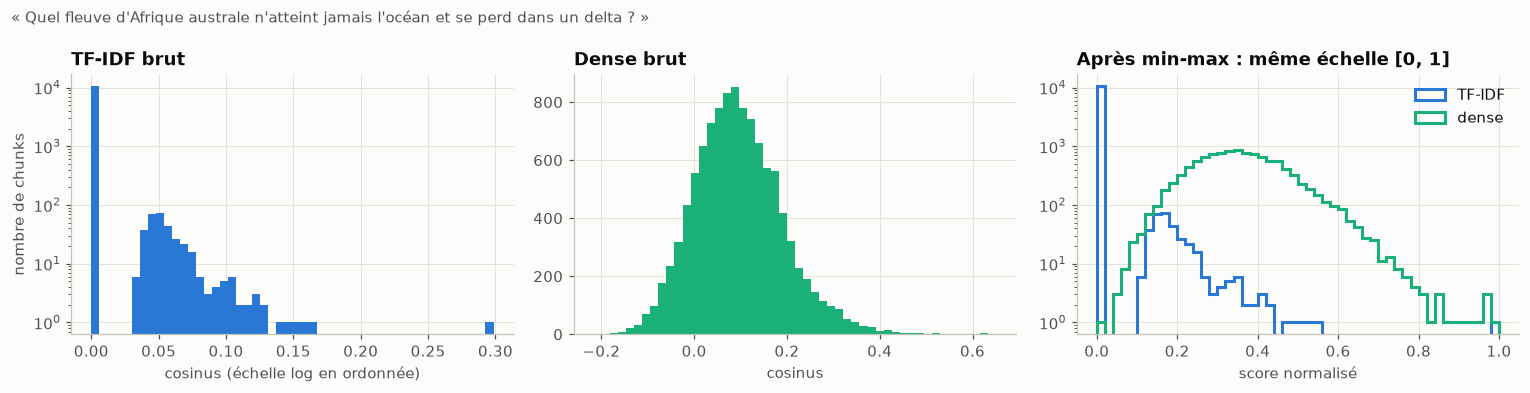

In [24]:
def minmax(s):
    lo, hi = s.min(), s.max()
    # Si tous les scores sont égaux (aucun mot de la requête dans le vocabulaire), on renvoie des zéros :
    # le TF-IDF n'apporte alors aucune information et ne doit pas perturber le classement.
    return np.zeros_like(s) if hi == lo else (s - lo) / (hi - lo)

def scores_hybrides(query, alpha=0.5, s_tfidf=None, s_dense=None):
    s_tfidf = scores_tfidf(query) if s_tfidf is None else s_tfidf
    s_dense = scores_dense(query) if s_dense is None else s_dense
    return alpha * minmax(s_dense) + (1 - alpha) * minmax(s_tfidf)

def search_hybrid(query, k=5, alpha=0.5):
    return top_k(scores_hybrides(query, alpha), k)

# Pourquoi normaliser : les distributions brutes des deux scores pour une même question
question_demo = "Quel fleuve d'Afrique australe n'atteint jamais l'océan et se perd dans un delta ?"
s_t, s_d = scores_tfidf(question_demo), scores_dense(question_demo)
print(f"TF-IDF : {np.mean(s_t == 0):.0%} de scores nuls, max {s_t.max():.3f} | "
      f"dense : min {s_d.min():.3f}, médiane {np.median(s_d):.3f}, max {s_d.max():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].hist(s_t, bins=50, color=BLEU)
axes[0].set_yscale("log")
axes[0].set_title("TF-IDF brut")
axes[0].set_xlabel("cosinus (échelle log en ordonnée)")
axes[1].hist(s_d, bins=50, color="#1baf7a")
axes[1].set_title("Dense brut")
axes[1].set_xlabel("cosinus")
for s, couleur, nom in ((minmax(s_t), BLEU, "TF-IDF"), (minmax(s_d), "#1baf7a", "dense")):
    axes[2].hist(s, bins=50, histtype="step", linewidth=2, color=couleur, label=nom)
axes[2].set_yscale("log")
axes[2].set_title("Après min-max : même échelle [0, 1]")
axes[2].set_xlabel("score normalisé")
axes[2].legend(frameon=False)
axes[0].set_ylabel("nombre de chunks")
fig.suptitle(f"« {question_demo} »", x=0.01, ha="left", fontsize=10, color=ENCRE_2)
fig.tight_layout()
sauver(fig, "09_echelles_scores")
plt.show()

#### Une même question posée aux trois fonctions

Deux questions, choisies pour faire apparaître les forces de chaque méthode : la première contient un nom propre rare, la seconde décrit son sujet sans jamais le nommer.

In [25]:
def comparer(query, k=5, alpha=0.5):
    res = {"TF-IDF": search_tfidf(query, k), "dense": search_dense(query, k), f"hybride α={alpha}": search_hybrid(query, k, alpha)}
    tableau = pd.DataFrame({nom: [f"{r['title']} ({r['score']:.2f})" for r in rs] for nom, rs in res.items()},
                           index=pd.RangeIndex(1, k + 1, name="rang"))
    print(f"Question : {query}")
    display(tableau)
    for nom, rs in res.items():
        print(f"  {nom:<14} n°1 : {rs[0]['text'][:150]!r}")
    print()

comparer("Qui a dirigé la thèse de Jean Paulhan ?")
comparer("Quel dieu égyptien serait né de lui-même à partir de l'océan primordial ?")

Question : Qui a dirigé la thèse de Jean Paulhan ?


,TF-IDF,dense,hybride α=0.5
rang,,,
1,Antoine Meillet (0.25),Années 1760 (0.57),Antoine Meillet (0.94)
2,James Henry Breasted (0.16),1693 (0.54),James Henry Breasted (0.76)
3,James Henry Breasted (0.15),1752 (0.54),Alan Greenspan (0.68)
4,Dennis Ritchie (0.14),Années 1880 (0.54),Antoine Meillet (0.65)
5,Exaxxion (0.13),Louis Corman (0.53),James Henry Breasted (0.64)


  TF-IDF         n°1 : 'Il a formé toute une génération de linguistes français, parmi lesquels Émile Benveniste, Marcel Cohen, Georges Dumézil, André Martinet, Aurélien Sauva'
  dense          n°1 : 'Personnages significatifs\n .\n James Cook, navigateur et cartographe.\n .\n Grigori Potemkine\n Jean-Jacques Rousseau\n John Wilkes\n\nChronologies thématiqu'
  hybride α=0.5  n°1 : 'Il a formé toute une génération de linguistes français, parmi lesquels Émile Benveniste, Marcel Cohen, Georges Dumézil, André Martinet, Aurélien Sauva'

Question : Quel dieu égyptien serait né de lui-même à partir de l'océan primordial ?


,TF-IDF,dense,hybride α=0.5
rang,,,
1,Min (dieu) (0.21),Harpocrate (0.66),Min (dieu) (0.92)
2,Ogdoade d'Hermopolis (0.21),Liste de divinités égyptiennes par ordre alpha...,Harpocrate (0.87)
3,Telmex (0.20),Liste de divinités égyptiennes par ordre alpha...,Ogdoade d'Hermopolis (0.86)
4,Atoum (0.17),Liste de divinités égyptiennes par ordre alpha...,Atoum (0.82)
5,Sobek (0.17),Drapeau de l'Égypte (0.63),Rê (0.79)


  TF-IDF         n°1 : "Les représentations du dieu Min sont nombreuses en Égypte et couvrent toute l'histoire pharaonique, faisant de lui l'un des dieux principaux du panthé"
  dense          n°1 : "Élevé en secret dans les marais du delta du Nil, le dieu, par la couronne qu'il porte, se présente comme héritier de son père et assimile progressivem"
  hybride α=0.5  n°1 : "Les représentations du dieu Min sont nombreuses en Égypte et couvrent toute l'histoire pharaonique, faisant de lui l'un des dieux principaux du panthé"



### 2.4 Mesurer plutôt que regarder : une petite évaluation

Une ou deux questions ne suffisent pas pour choisir α. On écrit donc **56 questions** dont la réponse se trouve dans le corpus : 2 par article pour 28 articles.

- Une question **lexicale** reprend les noms de l'article (« Quel processeur équipe l'Amstrad CPC 6128 ? »).
- Une question **paraphrasée** décrit le sujet sans le nommer (« Quel micro-ordinateur des années 1980 ajoutait un lecteur de disquette »).

Une réponse est correcte si un chunk de l'article attendu sort dans les premiers rangs. On utilise les mesures de classement du TP 3 :

- **Recall@k** : part des questions dont l'article attendu apparaît dans le top-k ;
- **MRR** : moyenne de `1 / rang` du premier chunk correct (1 s'il est premier, 0,5 s'il est deuxième, etc.).

On compare aussi une autre fusion, la **Reciprocal Rank Fusion** (RRF), qui additionne `1 / (60 + rang)` sur les deux classements au lieu des scores. Elle n'a besoin d'aucune normalisation.

In [26]:
QUESTIONS = [
    # (article attendu, question lexicale, question paraphrasée)
    ("Atoum", "Dans quelle ville le dieu Atoum était-il particulièrement vénéré ?",
     "Quelle divinité égyptienne serait née d'elle-même à partir de l'océan primordial ?"),
    ("Nekhbet", "De quelle région Nekhbet est-elle la déesse protectrice ?",
     "Quelle déesse égyptienne protégeait les accouchements et la royauté du Sud ?"),
    ("Mout", "Qui est l'époux de la déesse Mout dans la triade de Thèbes ?",
     "Quelle déesse mère égyptienne pouvait se changer en lionne ou en vautour ?"),
    ("Antoine Meillet", "Quelle chaire Antoine Meillet occupe-t-il au Collège de France en 1905 ?",
     "Quel spécialiste français des langues indo-européennes a formé toute une génération de linguistes ?"),
    ("André Martinet", "De quelle analyse André Martinet est-il considéré comme le père ?",
     "Quel linguiste français décrivait les sons des mots dès l'âge de huit ans ?"),
    ("Apple I", "Qui a conçu l'Apple I ?",
     "Quel fut le tout premier produit vendu par la marque à la pomme, en 1976 ?"),
    ("Amstrad CPC 6128", "Quel processeur équipe l'Amstrad CPC 6128 ?",
     "Quel micro-ordinateur des années 1980 ajoutait un lecteur de disquette et davantage de mémoire à son prédécesseur ?"),
    ("Turbo Pascal", "Qui a écrit le compilateur à l'origine de Turbo Pascal ?",
     "Quel outil de développement bon marché a popularisé un langage de programmation dans les années 1980 ?"),
    ("Forme de Backus-Naur", "À quoi sert la forme de Backus-Naur ?",
     "Quelle notation sert à écrire les règles de grammaire des langages de programmation ?"),
    ("John McCarthy", "Quel langage John McCarthy a-t-il créé en 1958 ?",
     "Quel chercheur américain, lauréat du prix Turing en 1971, est un pionnier de l'intelligence artificielle symbolique ?"),
    ("Simputer", "Dans quel pays le Simputer a-t-il été conçu ?",
     "Quel ordinateur bon marché a été pensé pour les populations rurales pauvres de l'Inde ?"),
    ("Fear, uncertainty and doubt", "Que signifie le sigle FUD ?",
     "Comment appelle-t-on la technique qui consiste à semer la peur pour influencer des clients ?"),
    ("Myéline", "Qui a inventé le terme myéline ?",
     "Quelle gaine isole les axones et accélère la conduction de l'influx nerveux ?"),
    ("Halophile", "Que signifie le mot halophile ?",
     "Comment appelle-t-on les organismes qui ont besoin de beaucoup de sel pour vivre ?"),
    ("Tétrachlorométhane", "Quelle est la formule brute du tétrachlorométhane ?",
     "Quel solvant chloré a été interdit parce qu'il détruit la couche d'ozone ?"),
    ("Candela", "Que mesure la candela ?",
     "Quelle unité a remplacé l'ancienne bougie pour mesurer la lumière d'une source ?"),
    ("(3753) Cruithne", "Qui a découvert l'astéroïde Cruithne ?",
     "Quel astéroïde est parfois surnommé à tort la seconde lune de la Terre ?"),
    ("Okavango", "Dans quel désert s'achève le cours de l'Okavango ?",
     "Quel fleuve d'Afrique australe n'atteint jamais l'océan et se perd dans un delta ?"),
    ("Shikoku", "Que signifie le nom Shikoku ?",
     "Quelle grande île japonaise était divisée en quatre provinces avant l'ère Meiji ?"),
    ("Harajuku", "Dans quel arrondissement de Tokyo se trouve Harajuku ?",
     "Quel quartier de Tokyo est devenu le quartier de la mode et du rock dans les années 1970 ?"),
    ("Dennis Tito", "Pourquoi Dennis Tito est-il connu ?",
     "Quel millionnaire américain a payé pour voyager dans l'espace en 2001 ?"),
    ("Étienne II (pape)", "À qui le pape Étienne II succède-t-il ?",
     "Quel pape fut le premier Italien après une longue série de pontifes orientaux ?"),
    ("Laurel Aitken", "Quel surnom les Anglais donnaient-ils à Laurel Aitken ?",
     "Quel chanteur jamaïcain d'origine cubaine est considéré comme un pionnier du ska et du reggae ?"),
    ("Confit de canard", "De quelle région vient le confit de canard ?",
     "Quelle spécialité culinaire du sud-ouest conserve la volaille dans sa graisse ?"),
    ("Anastylose", "Qu'est-ce que l'anastylose ?",
     "Comment appelle-t-on la reconstruction d'un monument en ruine avec ses propres fragments ?"),
    ("Mâchicoulis", "À quoi servait un mâchicoulis ?",
     "Quelle galerie en encorbellement permettait de lancer des projectiles au pied d'un rempart ?"),
    ("Vizir", "D'où vient le mot vizir ?",
     "Quel titre désignait le conseiller ou le ministre des califes et des sultans ?"),
    ("Frans Emil Sillanpää", "Quels sont les principaux romans de Frans Emil Sillanpää ?",
     "Quel écrivain finlandais a évoqué la guerre civile de son pays dans ses romans ?"),
]
eval_set = [(q, titre, style) for titre, q_lex, q_par in QUESTIONS
            for q, style in ((q_lex, "lexicale"), (q_par, "paraphrasée"))]
assert all(t in set(df["title"]) for _, t, _ in eval_set), "chaque article attendu doit être dans le corpus"
print(len(eval_set), "questions")

titres_chunks = np.array([c["title"] for c in chunks])

def rang_article(scores, titre, profondeur=100):
    # Rang (à partir de 1) du premier chunk de l'article attendu ; profondeur + 1 s'il n'est pas dans le top
    ordre = np.argsort(-scores)[:profondeur]
    trouves = np.flatnonzero(titres_chunks[ordre] == titre)
    return int(trouves[0]) + 1 if len(trouves) else profondeur + 1

def scores_rrf(s_tfidf, s_dense, k_rrf=60):
    # Reciprocal Rank Fusion : on additionne 1 / (k + rang) ; seul l'ordre compte, pas l'échelle des scores
    rangs = lambda s: np.argsort(np.argsort(-s)) + 1
    return 1 / (k_rrf + rangs(s_tfidf)) + 1 / (k_rrf + rangs(s_dense))

def evaluer(fn_tfidf, fn_dense, alphas=np.round(np.linspace(0, 1, 11), 1)):
    lignes = []
    for q, titre, style in eval_set:
        s_t, s_d = fn_tfidf(q), fn_dense(q)          # chaque score n'est calculé qu'une fois par question
        variantes = {"TF-IDF": s_t, "dense": s_d, "RRF": scores_rrf(s_t, s_d)}
        variantes.update({f"hybride α={a}": scores_hybrides(q, a, s_t, s_d) for a in alphas})
        for methode, s in variantes.items():
            lignes.append({"question": q, "article": titre, "style": style, "methode": methode,
                           "rang": rang_article(s, titre)})
    res = pd.DataFrame(lignes)
    res["R@1"], res["R@5"] = res["rang"] <= 1, res["rang"] <= 5
    res["MRR"] = np.where(res["rang"] <= 100, 1 / res["rang"], 0.0)
    return res

t0 = time.perf_counter()
eval_titre = evaluer(scores_tfidf, scores_dense)
print(f"Évaluation (avec titre) en {time.perf_counter() - t0:.0f} s")

def tableau_scores(res, methodes=("TF-IDF", "dense", "hybride α=0.5", "RRF")):
    t = res[res["methode"].isin(methodes)].pivot_table(index="methode", columns="style",
                                                       values=["R@1", "R@5", "MRR"], aggfunc="mean")
    t[("MRR", "toutes")] = res[res["methode"].isin(methodes)].groupby("methode")["MRR"].mean()
    return t.loc[list(methodes)].round(2)

tableau_scores(eval_titre)

56 questions


Évaluation (avec titre) en 4 s


MRR                  R@1                  R@5              \
style         lexicale paraphrasée lexicale paraphrasée lexicale paraphrasée   
methode                                                                        
TF-IDF            0.98        0.90     0.96        0.86     1.00        0.96   
dense             0.82        0.67     0.75        0.57     0.96        0.75   
hybride α=0.5     0.98        0.91     0.96        0.89     1.00        0.96   
RRF               0.96        0.77     0.93        0.68     1.00        0.89   

                 MRR  
style         toutes  
methode               
TF-IDF          0.94  
dense           0.75  
hybride α=0.5   0.95  
RRF             0.87

alpha          0.0    0.1    0.2   0.3    0.4    0.5    0.6    0.7    0.8    0.9    1.0
style                                                                                  
lexicale     0.982  0.982  0.982  1.00  0.982  0.982  0.982  0.982  0.982  0.958  0.823
paraphrasée  0.899  0.899  0.902  0.90  0.899  0.915  0.902  0.886  0.863  0.801  0.671
toutes       0.941  0.941  0.942  0.95  0.940  0.949  0.942  0.934  0.922  0.880  0.747

Meilleur α sur l'ensemble : 0.3 (MRR 0.950) | RRF : MRR 0.868


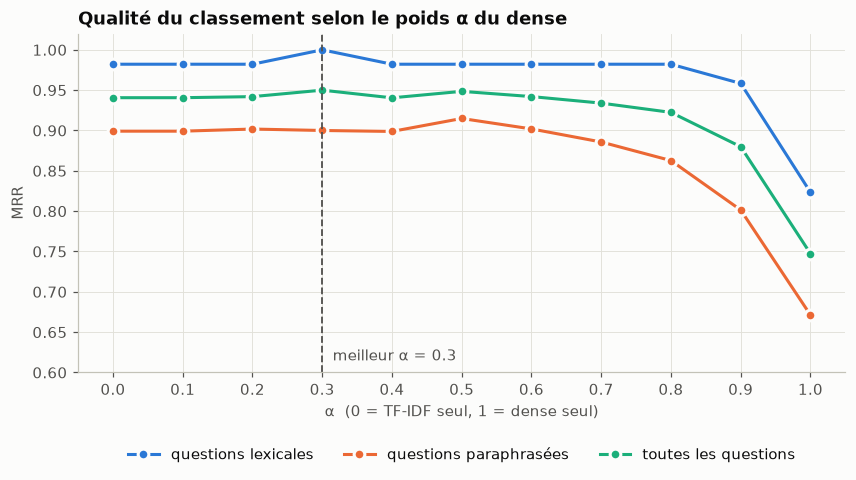

In [27]:
# Choix de α : MRR selon α, par style de question
alphas = np.round(np.linspace(0, 1, 11), 1)
hyb = eval_titre[eval_titre["methode"].str.startswith("hybride")].copy()
hyb["alpha"] = hyb["methode"].str.extract(r"α=([\d.]+)")[0].astype(float)
courbes = hyb.pivot_table(index="alpha", columns="style", values="MRR", aggfunc="mean")
courbes["toutes"] = hyb.groupby("alpha")["MRR"].mean()
alpha_meilleur = float(courbes["toutes"].idxmax())
print(courbes.round(3).T.to_string())
print(f"\nMeilleur α sur l'ensemble : {alpha_meilleur} (MRR {courbes['toutes'].max():.3f}) | "
      f"RRF : MRR {eval_titre.loc[eval_titre['methode'] == 'RRF', 'MRR'].mean():.3f}")

fig, ax = plt.subplots(figsize=(9, 4))
LIBELLES = {"lexicale": "questions lexicales", "paraphrasée": "questions paraphrasées", "toutes": "toutes les questions"}
for col, couleur in (("lexicale", "#2a78d6"), ("paraphrasée", "#eb6834"), ("toutes", "#1baf7a")):
    ax.plot(courbes.index, courbes[col], color=couleur, linewidth=2, marker="o", markersize=7,
            markeredgecolor="#fcfcfb", markeredgewidth=2, label=LIBELLES[col])
ax.axvline(alpha_meilleur, color=ENCRE_2, linewidth=1.2, linestyle="--")
ax.text(alpha_meilleur + 0.015, 0.615, f"meilleur α = {alpha_meilleur}", color=ENCRE_2)
ax.set_xticks(alphas)
ax.set_ylim(0.6, 1.02)          # courbe : l'axe n'a pas besoin de partir de 0
ax.set_xlabel("α  (0 = TF-IDF seul, 1 = dense seul)")
ax.set_ylabel("MRR")
ax.set_title("Qualité du classement selon le poids α du dense")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
sauver(fig, "10_choix_alpha")
plt.show()

#### Le préfixe de titre sert-il vraiment ?

Même évaluation sur un second index construit **sans** le titre en préfixe (TF-IDF et dense).

In [28]:
textes_sans_titre = [texte_indexe(c, avec_titre=False) for c in chunks]
vec_sans, X_sans = construire_tfidf(textes_sans_titre)
emb_sans = encoder_corpus(textes_sans_titre, "sans_titre")

eval_sans = evaluer(lambda q: scores_tfidf(q, vec_sans, X_sans), lambda q: scores_dense(q, emb_sans),
                    alphas=[0.5, alpha_meilleur])
methodes = ["TF-IDF", "dense", f"hybride α={alpha_meilleur}", "RRF"]
effet_titre = pd.DataFrame({
    "MRR sans titre": eval_sans.groupby("methode")["MRR"].mean(),
    "MRR avec titre": eval_titre.groupby("methode")["MRR"].mean(),
    "R@5 sans titre": eval_sans.groupby("methode")["R@5"].mean(),
    "R@5 avec titre": eval_titre.groupby("methode")["R@5"].mean(),
}).loc[methodes].round(2)
effet_titre

,MRR sans titre,MRR avec titre,R@5 sans titre,R@5 avec titre
methode,,,,
TF-IDF,0.91,0.94,0.96,0.98
dense,0.69,0.75,0.80,0.86
hybride α=0.3,0.91,0.95,0.96,0.98
RRF,0.90,0.87,0.96,0.95


In [29]:
# Les questions ratées par chaque méthode (rang > 5), avec titre : où sont les faiblesses ?
ratees = eval_titre[eval_titre["methode"].isin(["TF-IDF", "dense", f"hybride α={alpha_meilleur}"])
                    & (eval_titre["rang"] > 5)]
for methode, g in ratees.groupby("methode"):
    print(f"{methode} : {len(g)} questions hors du top 5")
    for r in g.itertuples():
        print(f"   [{r.style}] {r.question}  : rang {r.rang if r.rang <= 100 else '> 100'}")
    print()

TF-IDF : 1 questions hors du top 5
   [paraphrasée] Quel spécialiste français des langues indo-européennes a formé toute une génération de linguistes ?  : rang 7

dense : 8 questions hors du top 5
   [paraphrasée] Quelle divinité égyptienne serait née d'elle-même à partir de l'océan primordial ?  : rang 12
   [paraphrasée] Quelle déesse égyptienne protégeait les accouchements et la royauté du Sud ?  : rang 38
   [paraphrasée] Quel micro-ordinateur des années 1980 ajoutait un lecteur de disquette et davantage de mémoire à son prédécesseur ?  : rang 7
   [paraphrasée] Quel outil de développement bon marché a popularisé un langage de programmation dans les années 1980 ?  : rang 28
   [paraphrasée] Quelle notation sert à écrire les règles de grammaire des langages de programmation ?  : rang 25
   [lexicale] Dans quel pays le Simputer a-t-il été conçu ?  : rang 18
   [paraphrasée] Quelle grande île japonaise était divisée en quatre provinces avant l'ère Meiji ?  : rang 8
   [paraphrasée] Qu

### 2.5 Observations : les trois fonctions donnent-elles les mêmes chunks ?

**Non, et les différences sont systématiques.**

- **« Qui a dirigé la thèse de Jean Paulhan ? »** Le TF-IDF met le bon chunk d'« Antoine Meillet » en tête : « paulhan » est le mot le plus rare de la requête et reçoit le plus gros poids (0,65). Le dense renvoie des pages d'années (« Années 1760 », « 1693 »), c'est-à-dire des listes de personnages : il a encodé « une question sur une personne », pas le nom rare. L'hybride garde Meillet en tête (0,94).
- **« Quel dieu égyptien serait né de lui-même à partir de l'océan primordial ? »** Aucune méthode ne met Atoum premier. Le TF-IDF le classe 4e, derrière Min, l'Ogdoade d'Hermopolis et même « Telmex », une entreprise de télécommunications qui partage avec la question quelques mots isolés. Le dense comprend le **thème** (dieux égyptiens) mais pas le **détail** (l'auto-engendrement) : il remonte Harpocrate et les pages « Liste de divinités égyptiennes ». L'hybride le classe 4e.

**Sur les 56 questions de test** (MRR, de 0 à 1) :

| | lexicales | paraphrasées | toutes |
|---|---|---|---|
| TF-IDF | 0,98 | 0,90 | 0,94 |
| dense | 0,82 | 0,67 | 0,75 |
| hybride α = 0,5 | 0,98 | **0,91** | **0,95** |
| RRF | 0,96 | 0,77 | 0,87 |

- **L'hybride bat légèrement le TF-IDF seul**, grâce aux questions paraphrasées. La courbe est **plate pour α entre 0 et 0,6** : l'écart entre α = 0,3 (MRR 0,950) et α = 0,5 (0,949) est bien inférieur au poids d'une seule question (1/56, soit environ 0,018 sur Recall@k). On garde **α = 0,5** pour la partie 3 : c'est la meilleure valeur sur les questions paraphrasées, les plus proches de vraies questions d'utilisateur.
- **La RRF fait moins bien** que la fusion des scores : elle donne au classement dense, ici le plus faible, le même poids qu'au TF-IDF.
- **Le préfixe de titre aide toutes les méthodes fondées sur les scores** : TF-IDF passe de 0,91 à 0,94, le dense de 0,69 à 0,75 et l'hybride de 0,91 à 0,95.

**Pourquoi le dense déçoit ici :**

1. **Biais de l'évaluation.** J'ai écrit les questions en lisant les articles. Même « paraphrasées », elles gardent des mots rares du texte (« océan primordial », « encorbellement »), que le TF-IDF exploite. Sur de vraies questions d'utilisateurs, l'écart serait sans doute plus faible.
2. **Un modèle de paraphrase, pas de recherche.** MiniLM a appris à rapprocher deux phrases de même forme. Une recherche question-passage est **asymétrique** : une question courte d'un côté, un passage de 100 tokens de l'autre.
3. **Un seul vecteur par chunk.** Le mean pooling noie un nom rare (« Paulhan ») dans la moyenne d'une centaine de tokens.
4. **Les pages-listes** (années, listes de divinités) mentionnent beaucoup de sujets : leur vecteur moyen ressemble un peu à tout, et elles remontent sur des questions variées.

## Partie 3 : génération de la réponse (RAG)

Un LLM dispose de deux mémoires :

- une **mémoire paramétrique**, ce qu'il a appris pendant son entraînement, figée dans ses poids et invérifiable ;
- une **mémoire contextuelle** : le texte qu'on lui donne dans le prompt.

Le RAG (*Retrieval-Augmented Generation*) fournit à la mémoire contextuelle les passages trouvés par la recherche hybride. Il demande au modèle de répondre **à partir d'eux seulement**, en citant ses sources.

`Qwen2.5-1.5B-Instruct` est un Transformer **décodeur** : 1,54 milliard de paramètres, 28 couches, contexte de 32 768 tokens. Il génère un token à la fois, en choisissant à chaque pas selon `p(xₜ | x<t)`, la probabilité du token suivant sachant tous ceux qui le précèdent. Le suffixe *Instruct* indique qu'il a été ajusté pour suivre des consignes dans un format de conversation (système, utilisateur, assistant).

### 3.1 Chargement du modèle

Sur la T4 de Colab, on charge les poids en **float16** : 2 octets par paramètre, soit environ 3,1 Go de mémoire GPU. La T4 n'a pas de calcul bfloat16 rapide. Sans GPU, le code se replie sur le CPU en float32 : environ 6 Go de RAM, et une génération bien plus lente.

In [30]:
from transformers import AutoModelForCausalLM

device_llm = "cuda" if torch.cuda.is_available() else "cpu"
dtype_llm = torch.float16 if device_llm == "cuda" else torch.float32

tok_llm = AutoTokenizer.from_pretrained(model_decoder)
t0 = time.perf_counter()
llm = AutoModelForCausalLM.from_pretrained(
    model_decoder,
    dtype=dtype_llm,              # torch_dtype= dans les versions de transformers antérieures à 4.56
    low_cpu_mem_usage=True,       # charge les poids couche par couche au lieu de tout dupliquer en RAM
).to(device_llm)                  # sur Colab : .to("cuda"), comme le demande l'énoncé
llm.eval()                        # pas de dropout : la génération doit être déterministe

n_params = sum(p.numel() for p in llm.parameters())
taille_go = sum(p.numel() * p.element_size() for p in llm.parameters()) / 1e9
print(f"{model_decoder} chargé en {time.perf_counter() - t0:.0f} s sur {device_llm} ({dtype_llm})")
print(f"{n_params / 1e9:.2f} milliard de paramètres, {taille_go:.1f} Go de poids | "
      f"{llm.config.num_hidden_layers} couches, {llm.config.num_attention_heads} têtes de requête, "
      f"{llm.config.num_key_value_heads} têtes clé/valeur (GQA) | vocabulaire {llm.config.vocab_size}")

Qwen/Qwen2.5-1.5B-Instruct chargé en 5 s sur cpu (torch.float32)
1.54 milliard de paramètres, 6.2 Go de poids | 28 couches, 12 têtes de requête, 2 têtes clé/valeur (GQA) | vocabulaire 151936


### 3.2 Le prompt

On reprend le texte à trous de l'énoncé, en le découpant selon les rôles que le modèle a appris pendant son ajustement :

- le **message système** porte les règles, numérotées et formulées comme des obligations ;
- le **message utilisateur** porte les documents puis la question.

Trois ajouts par rapport à l'énoncé :

1. une **phrase de refus exacte** à reproduire, pour pouvoir détecter automatiquement les cas sans réponse ;
2. des **documents numérotés et titrés** (« [2] Halophile »), pour que le modèle cite ses sources et qu'on puisse vérifier ses citations ;
3. une **longueur imposée** (une à trois phrases) : un petit modèle qui écrit longtemps finit souvent par sortir des documents.

`apply_chat_template` insère les jetons spéciaux de Qwen (`<|im_start|>system`, `<|im_end|>`, etc.). Écrire ce format à la main est une source classique d'erreurs.

In [31]:
PHRASE_REFUS = "Je ne trouve pas la réponse dans les documents fournis."

SYSTEME = f'''Tu es un assistant qui répond à des questions à partir d'extraits de Wikipédia en français.
Règles :
1. Utilise uniquement les documents fournis. N'utilise jamais tes connaissances personnelles.
2. Si la réponse ne se trouve pas dans les documents, réponds exactement : « {PHRASE_REFUS} »
3. Cite entre crochets le numéro du ou des documents utilisés, par exemple [2].
4. Réponds en français, en une à trois phrases.'''

GABARIT = '''Documents :
{context}

Question : {question}'''

def formater_contexte(resultats):
    # Un bloc par chunk : numéro, titre de l'article, puis le texte
    return "\n\n".join(f"[{i}] {r['title']}\n{r['text']}" for i, r in enumerate(resultats, 1))

def construire_messages(question, context):
    return [{"role": "system", "content": SYSTEME},
            {"role": "user", "content": GABARIT.format(context=context, question=question)}]

# Le prompt exact que lit le modèle, jetons spéciaux compris
exemple = construire_messages("Qui a dirigé la thèse de Jean Paulhan ?",
                              formater_contexte(search_hybrid("Qui a dirigé la thèse de Jean Paulhan ?", k=2)))
prompt_exemple = tok_llm.apply_chat_template(exemple, tokenize=False, add_generation_prompt=True)
print(prompt_exemple)
print(f"--- {len(tok_llm(prompt_exemple)['input_ids'])} tokens avec 2 documents")

<|im_start|>system
Tu es un assistant qui répond à des questions à partir d'extraits de Wikipédia en français.
Règles :
1. Utilise uniquement les documents fournis. N'utilise jamais tes connaissances personnelles.
2. Si la réponse ne se trouve pas dans les documents, réponds exactement : « Je ne trouve pas la réponse dans les documents fournis. »
3. Cite entre crochets le numéro du ou des documents utilisés, par exemple [2].
4. Réponds en français, en une à trois phrases.<|im_end|>
<|im_start|>user
Documents :
[1] Antoine Meillet
Il a formé toute une génération de linguistes français, parmi lesquels Émile Benveniste, Marcel Cohen, Georges Dumézil, André Martinet, Aurélien Sauvageot, Lucien Tesnière, Joseph Vendryes, ainsi que le japonisant Charles Haguenauer. Antoine Meillet devait diriger la thèse de Jean Paulhan sur la sémantique du proverbe et c'est lui qui découvrit Gustave Guillaume.

[2] James Henry Breasted
James Henry Breasted étudie à l'université de Berlin, et prépare une thè

### 3.3 Le pipeline RAG : `ask_wikipedia`

Les quatre étapes de l'énoncé :

1. recherche hybride ;
2. concaténation des chunks dans `context` ;
3. insertion dans le prompt ;
4. génération.

**Décodage glouton** (`do_sample=False`) : à chaque pas, le token le plus probable. Pour une réponse factuelle, on veut la même réponse à chaque exécution, pas de la créativité. `repetition_penalty=1.05` évite qu'un petit modèle répète la même phrase en boucle.

La fonction prend aussi un `index` et un constructeur de prompt en paramètres : on pourra ainsi tester des améliorations sans réécrire le pipeline (sections 3.5 et 3.6).

In [32]:
@torch.inference_mode()               # pas de calcul de gradient : moins de mémoire, plus rapide
def generer(messages, max_new_tokens=200):
    texte = tok_llm.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    entrees = tok_llm(texte, return_tensors="pt").to(device_llm)
    sorties = llm.generate(
        **entrees,
        max_new_tokens=max_new_tokens,
        do_sample=False,                       # décodage glouton : réponse reproductible
        temperature=None, top_p=None, top_k=None,   # neutralise les réglages d'échantillonnage du modèle
        repetition_penalty=1.05,
        pad_token_id=tok_llm.eos_token_id,
    )
    nouveaux = sorties[0, entrees["input_ids"].shape[1]:]   # on ne décode que la suite, pas le prompt
    return tok_llm.decode(nouveaux, skip_special_tokens=True).strip(), entrees["input_ids"].shape[1], len(nouveaux)

# L'index de la partie 2, regroupé pour pouvoir en passer un autre
INDEX_V1 = {"nom": "index v1", "vec": vectorizer, "X": X_chunks, "emb": emb_chunks, "chunks": chunks}

def ask_wikipedia(query, k=5, alpha=0.5, max_new_tokens=200, verbeux=True,
                  index=INDEX_V1, construire=construire_messages):
    t0 = time.perf_counter()
    # 1. Recherche hybride (les deux scores bruts sont gardés pour le diagnostic)
    s_t = scores_tfidf(query, index["vec"], index["X"])
    s_d = scores_dense(query, index["emb"])
    resultats = top_k(scores_hybrides(query, alpha, s_t, s_d), k, base=index["chunks"])
    # 2. Concaténation des chunks
    context = formater_contexte(resultats)
    # 3. Insertion dans le prompt
    messages = construire(query, context)
    # 4. Génération
    reponse, n_prompt, n_gen = generer(messages, max_new_tokens)
    sortie = {"question": query, "chunks": resultats, "context": context, "reponse": reponse,
              "tokens_prompt": n_prompt, "tokens_generes": n_gen, "duree_s": time.perf_counter() - t0,
              "max_tfidf_brut": float(s_t.max()), "max_dense_brut": float(s_d.max())}
    if verbeux:
        print(f"QUESTION : {query}")
        print(f"(meilleurs cosinus bruts : TF-IDF {sortie['max_tfidf_brut']:.2f}, dense {sortie['max_dense_brut']:.2f})")
        display(afficher(resultats, largeur=90))
        print(f"RÉPONSE : {reponse}")
        print(f"[{n_prompt} tokens de prompt, {n_gen} générés, {sortie['duree_s']:.0f} s]\n")
    return sortie

def ask_sans_contexte(query, max_new_tokens=200):
    # Le même modèle, sans recherche : seule sa mémoire paramétrique répond
    messages = [{"role": "system", "content": "Tu es un assistant. Réponds en français, en une à trois phrases."},
                {"role": "user", "content": query}]
    return generer(messages, max_new_tokens)[0]

r = ask_wikipedia("Qui a dirigé la thèse de Jean Paulhan ?")

QUESTION : Qui a dirigé la thèse de Jean Paulhan ?
(meilleurs cosinus bruts : TF-IDF 0.25, dense 0.57)


,rang,score,article,extrait
0,1,0.944,Antoine Meillet,Il a formé toute une génération de linguistes ...
1,2,0.759,James Henry Breasted,James Henry Breasted étudie à l'université de ...
2,3,0.679,Alan Greenspan,"En 1953, il s'associa et fonda le cabinet de c..."
3,4,0.649,Antoine Meillet,"En 1897, il soutient sa thèse pour le doctorat..."
4,5,0.643,James Henry Breasted,Thèse reprise plus tard par Freud dans L'homme...


RÉPONSE : Antoine Meillet a dirigé la thèse de Jean Paulhan sur la sémantique du proverbe.
[565 tokens de prompt, 27 générés, 11 s]



#### Tests : des questions dont la réponse est dans l'échantillon, et des pièges

- **Six questions factuelles** dont la réponse se trouve dans le texte indexé.
- **Trois questions de date** sur des personnes dont l'étape 0 a montré que la date avait disparu du texte (« né le  à »).
- **Une question hors corpus.**

Pour chaque question, on vérifie automatiquement :

- **comportement attendu** : si la réponse figure dans les chunks indexés de l'article attendu, le modèle doit la donner ; sinon, il doit refuser ;
- **citation** : la réponse contient-elle un renvoi `[n]` ?
- **nombres non appuyés** : y a-t-il un nombre d'au moins deux chiffres qui n'apparaît dans aucun des documents fournis ? Ce test simple détecte une partie des hallucinations.

On pose aussi chaque question **au même modèle sans recherche**, pour voir ce que le RAG apporte et ce qu'il coûte.

In [33]:
TESTS = [
    # (question, réponses acceptées, article attendu ou None, preuve : motif qui doit figurer dans un chunk
    #  indexé de l'article pour qu'on considère la réponse comme présente dans l'index)
    ("Qui a dirigé la thèse de Jean Paulhan ?", ("Meillet",), "Antoine Meillet", r"diriger la thèse de Jean Paulhan"),
    ("Quel processeur équipe l'Amstrad CPC 6128 ?", ("Z80",), "Amstrad CPC 6128", r"Z80"),
    ("Qui a conçu l'Apple I ?", ("Wozniak",), "Apple I", r"Conçu par Steve Wozniak"),
    ("Que signifie le sigle FUD ?", ("peur", "fear"), "Fear, uncertainty and doubt", r"peur, incertitude et doute"),
    ("Comment appelle-t-on les organismes qui ont besoin de beaucoup de sel pour vivre ?", ("halophile",), "Halophile", r"halophile"),
    ("Quel fleuve d'Afrique australe n'atteint jamais l'océan ?", ("Okavango",), "Okavango", r"ne jamais rejoindre l'océan"),
    # Pour une date, il faut qu'elle soit écrite COMME date de naissance ou de décès :
    # « président (1966-1999) » contient 1999 mais ne dit pas quand Martinet est mort.
    ("En quelle année est né Antoine Meillet ?", ("1866",), "Antoine Meillet", r"(?:Naissance en|né le|né en)[^.;\n]{0,25}1866"),
    ("En quelle année est mort André Martinet ?", ("1999",), "André Martinet", r"(?:Décès en|mort le|mort en|meurt)[^.;\n]{0,25}1999"),
    ("En quelle année est né Dennis Tito ?", ("1940",), "Dennis Tito", r"(?:Naissance en|né le|né en)[^.;\n]{0,25}1940"),
    ("Qui a gagné la Coupe du monde de football 2018 ?", ("France",), None, None),
]

CITATION = re.compile(r"\[\d+(?:\s*[,;]\s*\d+)*\]")      # [2], mais aussi [1, 2, 3]

def contient(texte, mot):
    return strip_accents_unicode(mot.lower()) in strip_accents_unicode(texte.lower())

def refuse(texte):
    return contient(texte, "ne trouve pas") or contient(texte, "ne se trouve pas")

def reponse_dans_index(article, preuve, index):
    # La réponse est-elle écrite dans au moins un chunk indexé de l'article attendu ?
    if article is None:
        return False
    return any(re.search(preuve, c["text"]) for c in index["chunks"] if c["title"] == article)

def juger(sortie, acceptees, article, preuve, index):
    rep = sortie["reponse"]
    attendue = reponse_dans_index(article, preuve, index)
    sans_citations = CITATION.sub("", rep)
    return {
        "réponse dans l'index": attendue,
        "comportement attendu": any(contient(rep, a) for a in acceptees) if attendue else refuse(rep),
        "cite une source": bool(CITATION.search(rep)),
        "nombres non appuyés": [n for n in re.findall(r"\d{2,}", sans_citations) if n not in sortie["context"]],
    }

lignes = []
for question, acceptees, article, preuve in TESTS:
    rag = ask_wikipedia(question)                     # affiche la question, les chunks et la réponse
    seul = ask_sans_contexte(question)
    lignes.append({"question": question, **juger(rag, acceptees, article, preuve, INDEX_V1),
                   "réponse RAG": rag["reponse"], "réponse modèle seul": seul,
                   "modèle seul exact": any(contient(seul, a) for a in acceptees),
                   "cos dense brut": round(rag["max_dense_brut"], 2), "durée (s)": round(rag["duree_s"])})
bilan_v1 = pd.DataFrame(lignes)

QUESTION : Qui a dirigé la thèse de Jean Paulhan ?
(meilleurs cosinus bruts : TF-IDF 0.25, dense 0.57)


,rang,score,article,extrait
0,1,0.944,Antoine Meillet,Il a formé toute une génération de linguistes ...
1,2,0.759,James Henry Breasted,James Henry Breasted étudie à l'université de ...
2,3,0.679,Alan Greenspan,"En 1953, il s'associa et fonda le cabinet de c..."
3,4,0.649,Antoine Meillet,"En 1897, il soutient sa thèse pour le doctorat..."
4,5,0.643,James Henry Breasted,Thèse reprise plus tard par Freud dans L'homme...


RÉPONSE : Antoine Meillet a dirigé la thèse de Jean Paulhan sur la sémantique du proverbe.
[565 tokens de prompt, 27 générés, 12 s]



QUESTION : Quel processeur équipe l'Amstrad CPC 6128 ?
(meilleurs cosinus bruts : TF-IDF 0.54, dense 0.82)


,rang,score,article,extrait
0,1,1.000,Amstrad CPC 6128,L'Amstrad CPC 6128 est une évolution de l'Amst...
1,2,0.874,Amstrad CPC 6128,L'hebdomadaire Hebdogiciel annonça dans un num...
2,3,0.833,Amstrad CPC 6128,Amstrad 6128 plus L'Amstrad 6128 plus est sort...
3,4,0.817,Amstrad CPC 6128,Port parallèle 8 Bits. Sortie Stéréo par le m...
4,5,0.815,Amstrad CPC 6128,"La crainte d'une pénurie de ces disquettes , q..."


RÉPONSE : Le CPC 6128 est équipé du même processeur Z80 à 4 MHz que l'Amstrad CPC 464.
[696 tokens de prompt, 34 générés, 14 s]



... (20 outputs left out)

RÉPONSE : Dennis Tito est né en 1945. [2]
[531 tokens de prompt, 17 générés, 11 s]



QUESTION : Qui a gagné la Coupe du monde de football 2018 ?
(meilleurs cosinus bruts : TF-IDF 0.24, dense 0.51)


,rang,score,article,extrait
0,1,0.982,Ruslan Ponomariov,Finaliste de la coupe du monde (2005 et 2009) ...
1,2,0.777,Fred,"Football Helbert Frederico Carreiro da Silva,..."
2,3,0.744,Produit intérieur brut des États-Unis,"2016-2017 : 4,3 % 2017-2018 : 5,4 % 2018-2019 ..."
3,4,0.714,Parti action nationale,Ricardo Anaya Cortés 2015–2017 Damián Zepeda V...
4,5,0.668,Liste alphabétique des sports,E Échecs Équitation Escalade Escrime Espo...


RÉPONSE : Je ne trouve pas la réponse dans les documents fournis.
[659 tokens de prompt, 13 générés, 13 s]



In [34]:
pd.set_option("display.max_colwidth", 120)
print(f"RAG : {bilan_v1['comportement attendu'].sum()} / {len(bilan_v1)} comportements attendus | "
      f"{bilan_v1['cite une source'].sum()} réponses citent une source | "
      f"modèle seul : {bilan_v1['modèle seul exact'].sum()} / {len(bilan_v1)} faits exacts")
bilan_v1[["question", "réponse dans l'index", "comportement attendu", "cite une source",
          "nombres non appuyés", "modèle seul exact", "cos dense brut"]]

RAG : 7 / 10 comportements attendus | 2 réponses citent une source | modèle seul : 4 / 10 faits exacts


,question,réponse dans l'index,comportement attendu,cite une source,nombres non appuyés,modèle seul exact,cos dense brut
0,Qui a dirigé la thèse de Jean Paulhan ?,True,True,False,[],False,0.57
1,Quel processeur équipe l'Amstrad CPC 6128 ?,True,True,False,[],True,0.82
2,Qui a conçu l'Apple I ?,True,True,False,[],True,0.77
3,Que signifie le sigle FUD ?,True,True,False,[],False,0.57
4,Comment appelle-t-on les organismes qui ont besoin de beaucoup de sel pour vivre ?,True,True,False,[],True,0.66
5,Quel fleuve d'Afrique australe n'atteint jamais l'océan ?,True,True,True,[],False,0.65
6,En quelle année est né Antoine Meillet ?,False,False,False,[1866],False,0.70
7,En quelle année est mort André Martinet ?,False,False,False,[1970],False,0.62
8,En quelle année est né Dennis Tito ?,False,False,True,[1945],False,0.71
9,Qui a gagné la Coupe du monde de football 2018 ?,False,True,False,[],True,0.51


In [35]:
# Les réponses en entier, côte à côte
for l in lignes:
    print(f"■ {l['question']}")
    print(f"   RAG         : {l['réponse RAG']}")
    print(f"   modèle seul : {l['réponse modèle seul']}\n")

■ Qui a dirigé la thèse de Jean Paulhan ?
   RAG         : Antoine Meillet a dirigé la thèse de Jean Paulhan sur la sémantique du proverbe.
   modèle seul : Jean Paulhan a dirigé sa propre thèse de doctorat.

■ Quel processeur équipe l'Amstrad CPC 6128 ?
   RAG         : Le CPC 6128 est équipé du même processeur Z80 à 4 MHz que l'Amstrad CPC 464.
   modèle seul : L'Amstrad CPC 6128 est équipée d'un processeur Z80 de 4 MHz.

■ Qui a conçu l'Apple I ?
   RAG         : Steve Wozniak, Steve Jobs et Ronald Wayne ont conçu l'Apple I.
   modèle seul : L'Apple I a été conçu par Steve Wozniak.

■ Que signifie le sigle FUD ?
   RAG         : Le sigle FUD signifie "Fear, uncertainty and doubt". Il est utilisé de manière anecdotique à propos de l'attitude de certains acteurs du mouvement open source, mais aussi dans le contexte de la sécurité informatique, où il peut être utilisé comme une stratégie marketing pour dénigrer un produit, un service, une monnaie, voire une personne d'une société concu

### 3.4 Diagnostic : d'où vient « 1866 » ?

Le RAG répond « Antoine Meillet est né en 1866 ». C'est exact, mais le test des nombres non appuyés signale que **1866 n'apparaît dans aucun des cinq documents fournis**. Le modèle a puisé dans sa mémoire paramétrique, en violation de la règle 1. Il est tombé juste ici, alors que sans contexte il répondait 1863 : la même mécanique produit aussi des erreurs.

Pourquoi le document ne contenait-il pas la date ? Retour aux données brutes.

In [36]:
brut = df.loc[df["title"] == "Antoine Meillet", "body"].iloc[0]
print("Début du texte  :", repr(brut[:110]))
print("Fin de l'article :", brut.splitlines()[-9:])
print("'1866' dans le texte brut :", "1866" in brut, "| dans le texte nettoyé (partie 1) :", "1866" in textes[df.loc[df['title'] == 'Antoine Meillet', 'doc_id'].iloc[0]])

CATEGORIE_DATEE = re.compile(r"(?m)^(?:Naissance|Décès) (?:en|à|dans) [^\n]+$")
trou_date = df["body"].str.contains(r"\b(?:né|née|mort|morte|le)\s{2,}(?:à|en|et|,)")
a_categorie = df["body"].map(lambda b: bool(re.search(r"(?m)^(?:Naissance|Décès) en [^\n]*\d{3,4}", b)))
garde = df["texte"].map(lambda t: bool(CATEGORIE_DATEE.search(t)))
print(f"\nArticles avec une date dans leurs catégories : {a_categorie.sum()} | "
      f"catégories encore présentes après le nettoyage de la partie 1 : {garde.sum()}")
print(f"Articles avec un trou de date dans le texte : {trou_date.sum()} | "
      f"dont date récupérable dans les catégories : {(trou_date & a_categorie).sum()}")

Début du texte  : 'Paul Jules Antoine Meillet, né le  à Moulins (Allier) et mort le  à Châteaumeillant (Cher), est le principal l'
Fin de l'article : ['Arménologue français', 'Indo-européaniste', "Étudiant de l'université de Paris", 'Naissance en novembre 1866', 'Naissance à Moulins (Allier)', 'Décès en septembre 1936', 'Décès à 69 ans', 'Décès dans le Cher', 'Personnalité inhumée à Moulins']
'1866' dans le texte brut : True | dans le texte nettoyé (partie 1) : False



Articles avec une date dans leurs catégories : 150 | catégories encore présentes après le nettoyage de la partie 1 : 40
Articles avec un trou de date dans le texte : 110 | dont date récupérable dans les catégories : 79


Le diagnostic de l'étape 0 était **incomplet**. L'extraction a bien effacé la date du texte (« né le  à Moulins »), mais Wikipédia la range aussi dans les **catégories** de fin d'article : « Naissance en novembre 1866 », « Décès en septembre 1936 ». C'est notre nettoyage de la partie 1, en coupant tout ce qui suit la première section de fin, qui a supprimé ces lignes.

### 3.5 Amélioration 1 : une fiche par article à partir des catégories

On ne revient pas sur le découpage : on **ajoute** à l'index un petit chunk par article, qui regroupe ses catégories de naissance et de décès. Il n'y a pas besoin de tout réencoder : on réajuste le TF-IDF (1 s) et on n'encode que les nouvelles fiches, qu'on empile sous la matrice dense existante.

In [37]:
fiches = []
for doc in df.itertuples(index=False):
    faits = list(dict.fromkeys(f.strip() for f in CATEGORIE_DATEE.findall(doc.body)))   # sans doublons, dans l'ordre
    if faits:
        texte = " ; ".join(faits) + "."
        fiches.append({"chunk_id": f"{doc.doc_id}-fic-000", "doc_id": doc.doc_id, "title": doc.title, "url": doc.url,
                       "methode": "fiche_categories", "position": -1, "n_chunks_doc": 1,
                       "debut": None, "fin": None, "text": texte, "n_car": len(texte), "n_tokens": None})
print(f"{len(fiches)} fiches | exemple : {texte_indexe(fiches[0])!r}")

chunks_v2 = chunks + fiches
vec_v2, X_v2 = construire_tfidf([texte_indexe(c) for c in chunks_v2])
emb_fiches = encodeur.encode([texte_indexe(f) for f in fiches], normalize_embeddings=True, convert_to_numpy=True)
INDEX_V2 = {"nom": "index v2", "vec": vec_v2, "X": X_v2,
            "emb": np.vstack([emb_chunks, emb_fiches]),          # mêmes vecteurs pour les chunks existants
            "chunks": chunks_v2}
print(f"index v2 : {len(chunks_v2)} chunks, TF-IDF {X_v2.shape}, dense {INDEX_V2['emb'].shape}")

154 fiches | exemple : 'Antoine Meillet : Naissance en novembre 1866 ; Naissance à Moulins (Allier) ; Décès en septembre 1936 ; Décès à 69 ans ; Décès dans le Cher.'


index v2 : 11080 chunks, TF-IDF (11080, 47880), dense (11080, 384)


### 3.6 Amélioration 2 : un prompt avec exemples

Dans les tests, le modèle cite rarement ses sources, malgré la règle 3. Un petit modèle suit mieux une consigne qu'on lui **montre** que celle qu'on lui **décrit**. Le prompt v2 ajoute deux échanges d'exemple (*few-shot*) : une réponse citée et un refus. Il répète aussi les règles **après** les documents, là où le modèle les lit en dernier, juste avant d'écrire.

In [38]:
EXEMPLE_DOCS = ("[1] Tour Eiffel\nLa tour Eiffel est une tour de fer puddlé de Paris, construite par l'entreprise "
                "de Gustave Eiffel pour l'Exposition universelle de 1889.")
RAPPEL = ("Rappel : réponds uniquement à partir des documents ci-dessus, cite-les entre crochets, "
          f"et si la réponse n'y est pas écrite, réponds exactement : « {PHRASE_REFUS} »")

def construire_messages_v2(question, context):
    return [
        {"role": "system", "content": SYSTEME},
        # Exemple 1 : une réponse appuyée sur un document, avec sa citation
        {"role": "user", "content": GABARIT.format(context=EXEMPLE_DOCS, question="Pour quel événement la tour Eiffel a-t-elle été construite ?")},
        {"role": "assistant", "content": "Pour l'Exposition universelle de 1889 [1]."},
        # Exemple 2 : la réponse n'est pas dans le document, même si le modèle la « connaît »
        {"role": "user", "content": GABARIT.format(context=EXEMPLE_DOCS, question="Combien de visiteurs la tour Eiffel reçoit-elle chaque année ?")},
        {"role": "assistant", "content": PHRASE_REFUS},
        # La vraie question, suivie du rappel des règles
        {"role": "user", "content": GABARIT.format(context=context, question=question) + "\n\n" + RAPPEL},
    ]

def evaluer_rag(index, construire, nom):
    res = []
    for question, acceptees, article, preuve in TESTS:
        s = ask_wikipedia(question, verbeux=False, index=index, construire=construire)
        res.append({"configuration": nom, "question": question, "réponse": s["reponse"],
                    "durée (s)": s["duree_s"], **juger(s, acceptees, article, preuve, index)})
    return pd.DataFrame(res)

bilan_v1["configuration"] = "A : prompt v1, index v1"
bilan_b = evaluer_rag(INDEX_V2, construire_messages, "B : prompt v1, index v2 (fiches)")
bilan_c = evaluer_rag(INDEX_V2, construire_messages_v2, "C : prompt v2, index v2")

tous = pd.concat([bilan_v1.rename(columns={"réponse RAG": "réponse"}), bilan_b, bilan_c], ignore_index=True)
synthese = tous.groupby("configuration", sort=False).agg(
    comportements_attendus=("comportement attendu", "sum"),
    citent_une_source=("cite une source", "sum"),
    reponses_avec_nombre_non_appuye=("nombres non appuyés", lambda s: sum(len(x) > 0 for x in s)),
    duree_moyenne_s=("durée (s)", "mean"),
).round(1)
synthese["sur"] = len(TESTS)
synthese

,comportements_attendus,citent_une_source,reponses_avec_nombre_non_appuye,duree_moyenne_s,sur
configuration,,,,,
"A : prompt v1, index v1",7,2,3,18.3,10
"B : prompt v1, index v2 (fiches)",10,2,0,17.6,10
"C : prompt v2, index v2",8,6,0,19.2,10


In [39]:
# Réponses des trois configurations, question par question
for q in [t[0] for t in TESTS]:
    print(f"■ {q}")
    for _, l in tous[tous["question"] == q].iterrows():
        drapeaux = ("ok" if l["comportement attendu"] else "KO") + (" [cite]" if l["cite une source"] else "") \
                   + (f" nombres non appuyés {l['nombres non appuyés']}" if l["nombres non appuyés"] else "")
        print(f"   {l['configuration'][:1]} {drapeaux:<12} {l['réponse'][:160]}")
    print()

■ Qui a dirigé la thèse de Jean Paulhan ?
   A ok           Antoine Meillet a dirigé la thèse de Jean Paulhan sur la sémantique du proverbe.
   B ok           Antoine Meillet a dirigé la thèse de Jean Paulhan sur la sémantique du proverbe.
   C ok           Antoine Meillet a dirigé la thèse de Jean Paulhan sur la sémantique du proverbe.

■ Quel processeur équipe l'Amstrad CPC 6128 ?
   A ok           Le CPC 6128 est équipé du même processeur Z80 à 4 MHz que l'Amstrad CPC 464.
   B ok           Le CPC 6128 est équipé du même processeur Z80 à 4 MHz que l'Amstrad CPC 464.
   C ok [cite]    Le CPC 6128 est équipé du processeur Z80 à 4 MHz [1].

■ Qui a conçu l'Apple I ?
   A ok           Steve Wozniak, Steve Jobs et Ronald Wayne ont conçu l'Apple I.
   B ok           Steve Wozniak, Steve Jobs et Ronald Wayne ont conçu l'Apple I.
   C ok [cite]    Steve Wozniak, Steve Jobs et Ronald Wayne ont conçu l'Apple I [1].

■ Que signifie le sigle FUD ?
   A ok           Le sigle FUD signifie "Fear, 

### 3.7 Observations

**Ce que le RAG apporte.** Sur les six questions factuelles, le RAG répond juste six fois. Le modèle seul n'a raison que sur ce qui est très connu (le Z80, Wozniak, les halophiles) ; ailleurs, il invente avec assurance : « Jean Paulhan a dirigé sa propre thèse », « FUD : *False Usability Demonstration* », « le fleuve Victoria ».

**Ce que le RAG coûte.** Il refuse ce qu'il ne trouve pas, même quand le modèle « sait » : la victoire de la France en 2018 n'est pas dans le corpus, donc le RAG refuse. C'est le contrat voulu : une réponse vérifiable, ou rien.

**Le piège des dates (configuration A).** Les trois questions de date révèlent le pire comportement d'un RAG : répondre avec assurance une date **absente des documents**. Elle est juste par chance pour Meillet (1866), fausse pour Martinet (1970 au lieu de 1999) et pour Dennis Tito (1945 au lieu de 1940). Pour Tito, la réponse porte en plus une **citation [2] qui ne contient pas la date** : une citation ne prouve rien tant qu'on ne la vérifie pas. Le test des nombres non appuyés détecte les trois cas.

**Amélioration 1, les fiches (B) : 10/10.** La cause était dans les **données**, pas dans le modèle : les dates existaient dans les catégories, et notre nettoyage les supprimait. Les 154 fiches les remettent dans l'index. Les trois dates deviennent justes et appuyées (« mort en juillet 1999 », « né en août 1940 [2] »), sans aucun nombre inventé.

**Amélioration 2, des exemples dans le prompt (C) : un compromis.** Les réponses citent plus souvent leur source et sont plus courtes. En revanche, le modèle **refuse** désormais deux réponses présentes dans le contexte (Meillet, Martinet). La fiche est une liste de catégories et non une phrase, et l'exemple de refus a rendu le modèle trop prudent. Un modèle plus fidèle refuse aussi plus souvent : c'est un arbitrage entre précision et rappel. Il faut le régler sur bien plus de dix questions, sinon on ajuste le prompt à ses propres tests.

**Le min-max ne sait pas dire « rien trouvé ».** Pour la Coupe du monde 2018, le meilleur chunk (un joueur d'échecs « finaliste de la coupe du monde ») reçoit un score hybride de 0,98 après normalisation. Son cosinus dense brut (0,51) est le plus bas des tests, mais à peine sous celui d'une question réussie (Paulhan, 0,57) : un seuil ne séparerait pas proprement les deux cas. Ici, c'est le LLM qui a fait le tri.

**Coût.** Sur CPU, 10 à 40 s par question pour des prompts de 400 à 700 tokens. Sur une T4, quelques secondes.